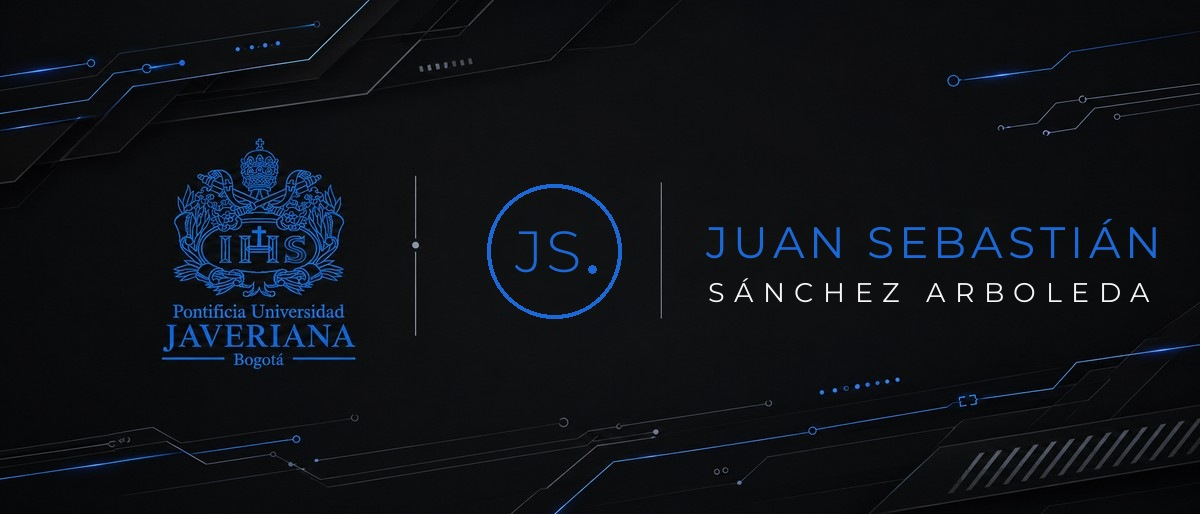

# Cuaderno Salario · PySpark y modelos de Machine Learning

**Juan Sebastián Sánchez Arboleda**
Procesamiento de Alto Volumen de Datos · Pontificia Universidad Javeriana
Fecha de entrega · 23 de noviembre de 2026

## Contexto

El conjunto **Census Income**, más conocido como *Adult*, es uno de los datasets clásicos del repositorio de la UCI. Barry Becker lo extrajo de la base del **censo de Estados Unidos de 1994** y Ronny Kohavi lo usó en 1996 para comparar algoritmos de clasificación. La tarea que propone es directa: a partir de datos demográficos y laborales de una persona, decidir si sus ingresos superan los **50.000 dólares al año**.

Trabajo con los dos archivos originales de la [página del dataset](https://archive.ics.uci.edu/dataset/20/census+income), guardados en HDFS. `adult.data` trae **32.561 registros** y `adult.test` otros **16.281**, para un total de **48.842**. Cada registro tiene 14 atributos (edad, clase de trabajo, peso muestral, nivel y años de educación, estado civil, ocupación, parentesco, raza, sexo, ganancia y pérdida de capital, horas trabajadas por semana y país de origen) y la etiqueta de ingreso, que vale `<=50K` o `>50K`.

Este problema es distinto al del cuaderno ICTUS. Allá la clase positiva era el 4,9 % de los datos, y aquí cerca de una de cada cuatro personas gana más de 50K. Entonces la pregunta con la que arranqué fue otra: si una regla que siempre responde «≤ 50K» ya acierta en tres de cada cuatro casos, ¿cuánto agregan realmente los modelos de MLlib, y cuál de ellos encuentra mejor a las personas con ingresos altos?

## Objetivos

**Objetivo general.** Construir y comparar con PySpark y Spark MLlib varios modelos de clasificación que predigan si una persona gana más de 50.000 dólares al año a partir de los datos del censo, y documentar cada fase del proceso.

**Objetivos específicos.**

1. Leer `adult.data` y `adult.test` desde el data lake (HDFS) y describir su estructura, sus tipos, sus faltantes y el balance entre clases.
2. Preparar los datos: ajustar nombres y tipos, unificar la etiqueta de los dos archivos, tratar los faltantes, quitar las columnas redundantes y codificar las categóricas.
3. Entrenar **ocho** clasificadores de MLlib, tres más del mínimo que pide la guía, sobre la partición original de entrenamiento.
4. Evaluarlos sobre `adult.test` con exactitud, precisión, recall, F1, ROC AUC y AUC PR, contrastarlos con una línea base que siempre predice 0 y medir qué cambia al entrenarlos con pesos por clase.
5. Analizar los resultados, revisar qué variables pesan más en el mejor modelo y concluir cuál conviene y con qué limitaciones.

## Desarrollo y documentación

Igual que en el cuaderno ICTUS, organicé el trabajo siguiendo CRISP-DM. Esta tabla resume qué hice en cada fase y en qué parte del cuaderno queda.

| Fase | Cómo la trabajé |
| --- | --- |
| Comprensión del negocio | Formulé la predicción del rango de ingresos como un problema de clasificación binaria para la materia (Contexto y Objetivos). |
| Comprensión de los datos | Revisé los archivos crudos, las dimensiones, los tipos, los faltantes, las distribuciones y la relación de cada variable con la etiqueta (sección 1). |
| Preparación | Renombré columnas, unifiqué la etiqueta, traté los faltantes, agrupé el país, quité columnas redundantes y armé el vector de entrada (secciones 1 y 2). |
| Modelado | Ajusté los ocho clasificadores sobre la misma partición de entrenamiento (sección 3). |
| Evaluación | Los medí con el mismo conjunto de prueba, los comparé con una regla que siempre responde cero y repetí el ejercicio con pesos por clase (sección 4 y Análisis de resultados). |
| Despliegue | Entrego un cuaderno reproducible como producto académico. |

### Entorno de trabajo

Desarrollé el cuaderno en el servidor del curso, con el kernel **rapKernel_v4** y el Spark instalado en el clúster. La primera celda detecta si está en el servidor y, en ese caso, inicializa Spark con `findspark`. Allí los dos archivos se leen desde la carpeta `/Formatos1255/SanchezSalario` de HDFS.

Para revisarlo fuera del servidor, el código también acepta `adult.data` y `adult.test` en la misma carpeta del notebook, o en la ruta que se indique en la variable de entorno `ADULT_DIR`. En ese caso las bibliotecas se instalan aparte con `%pip install pyspark==3.5.5 setuptools "pandas<3" matplotlib seaborn scikit-learn` y Java se configura por fuera. [Guía de instalación de PySpark](https://spark.apache.org/docs/3.5.5/api/python/getting_started/install.html)

### De dónde sale cada herramienta

Me mantuve en lo que hemos trabajado en el curso: el laboratorio de Spark, el tutorial de Spark, el taller de Stroke, el cuaderno ICTUS y las dos guías que acompañan este taller. La tabla indica de dónde tomé cada cosa. Lo único que no aparece en ninguno de esos materiales es la opción `comment` del lector de CSV, así que en la sección 1 dejo un ejemplo pequeño de cómo funciona. También hay un ejemplo de `vector_to_array` en la sección 4.

| Herramienta | Para qué la uso | Dónde la vimos | Documentación |
| --- | --- | --- | --- |
| `hadoop fs -ls`, `textFile`, `map`, `filter`, `countByValue` | Revisar los archivos crudos en HDFS | Laboratorio de Spark | [RDD Programming Guide](https://spark.apache.org/docs/3.5.5/rdd-programming-guide.html) |
| `read.format("csv")` con `header`, `inferSchema`, `delimiter` | Leer los archivos como DataFrame | Laboratorio de Spark y taller de Stroke | [CSV Files](https://spark.apache.org/docs/3.5.5/sql-data-sources-csv.html) |
| `option("nullValue", ...)` | Convertir los `?` en nulos | Cuaderno ICTUS | [CSV Files](https://spark.apache.org/docs/3.5.5/sql-data-sources-csv.html) |
| `option("comment", "|")` | Saltar la primera línea de `adult.test` | **Nueva** (ejemplo en la sección 1) | [CSV Files](https://spark.apache.org/docs/3.5.5/sql-data-sources-csv.html) |
| `StringIndexer`, `OneHotEncoder`, `VectorAssembler`, `StandardScaler`, `Pipeline` | Armar el vector de entrada | Tutorial de Spark y taller de Stroke | [Extracting, transforming and selecting features](https://spark.apache.org/docs/3.5.5/ml-features.html) |
| `DecisionTreeClassifier`, `RandomForestClassifier`, `NaiveBayes` | Tres de los ocho modelos | Tutorial de Spark | [Árbol](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html#decision-tree-classifier) · [Bosque](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html#random-forest-classifier) · [Naive Bayes](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html#naive-bayes) |
| `LogisticRegression`, `GBTClassifier`, `LinearSVC`, `FMClassifier` | Cuatro modelos más | Guía de clasificación con PySpark (GUIA01) | [Logística](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html#logistic-regression) · [GBT](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html#gradient-boosted-tree-classifier) · [SVM](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html#linear-support-vector-machine) · [FM](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html#factorization-machines-classifier) |
| `MultilayerPerceptronClassifier`, `vector_to_array` | El octavo modelo y los puntajes para las curvas | Cuaderno ICTUS | [Perceptrón](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html#multilayer-perceptron-classifier) · [vector_to_array](https://spark.apache.org/docs/3.5.5/api/python/reference/api/pyspark.ml.functions.vector_to_array.html) |
| `MulticlassClassificationEvaluator` | Exactitud, precisión, recall y F1 de la clase 1 (`fMeasureByLabel`) | Tutorial de Spark y taller de Stroke | [Referencia](https://spark.apache.org/docs/3.5.5/api/python/reference/api/pyspark.ml.evaluation.MulticlassClassificationEvaluator.html) |
| `BinaryClassificationEvaluator` | ROC AUC y AUC PR | GUIA01 y taller de Stroke | [Referencia](https://spark.apache.org/docs/3.5.5/api/python/reference/api/pyspark.ml.evaluation.BinaryClassificationEvaluator.html) |
| `weightCol` y `featureImportances` | Pesos por clase e importancia de variables | Taller de Stroke | [Clasificadores de Spark ML](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html) |

In [1]:
## Bibliotecas generales
import os
import time
from pathlib import Path
import numpy as np                 # arreglos numéricos
import pandas as pd                # tablas pequeñas en memoria (para graficar y resumir)

## Spark del servidor del curso: findspark ubica la instalación del clúster
spark_del_curso = Path("/mnt/sda1/Cluster/Spark")
en_servidor = spark_del_curso.is_dir()
if en_servidor:
    import findspark
    findspark.init(str(spark_del_curso))

## Bibliotecas para graficar
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

## Sesión Spark y funciones sobre DataFrames
from pyspark.sql import SparkSession, functions as F

## MLlib: preparación de variables
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler

## MLlib: los ocho clasificadores que comparo
from pyspark.ml.classification import (
    DecisionTreeClassifier, RandomForestClassifier, NaiveBayes,      # vistos en el tutorial de Spark
    LogisticRegression, GBTClassifier, LinearSVC, FMClassifier,      # de la guía de clasificación
    MultilayerPerceptronClassifier,                                  # usado en el cuaderno ICTUS
)

## MLlib: evaluadores
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

## scikit-learn: solo para la matriz de confusión y los puntos de las curvas
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
azul, naranja = "#1361ad", "#c36927"
paleta = [azul, naranja, "#4f8d78", "#8268a5", "#687682", "#b8a03a", "#b0527a", "#3aa0a8"]

In [2]:
## Carpeta de HDFS donde están adult.data y adult.test (en el servidor)
carpeta_hdfs = "hdfs://10.195.34.34:9000/Formatos1255/SanchezSalario"
## Carpeta local, solo para revisar el cuaderno fuera del servidor
carpeta_local = os.environ.get("ADULT_DIR", ".")

carpeta_datos = os.environ.get("ADULT_HDFS", carpeta_hdfs) if en_servidor else carpeta_local
usar_hdfs = carpeta_datos.startswith("hdfs://")
if not usar_hdfs:
    for archivo in ["adult.data", "adult.test"]:
        if not (Path(carpeta_datos) / archivo).is_file():
            raise FileNotFoundError(f"No encontré {archivo} en {carpeta_datos}. Mira la sección Entorno de trabajo.")


def ruta(archivo):
    """Devuelve la ruta completa de un archivo: en HDFS o como URI local."""
    if usar_hdfs:
        return f"{carpeta_datos}/{archivo}"
    return (Path(carpeta_datos) / archivo).resolve().as_uri()


## Sesión Spark (Spark + apellido del autor)
sesion = SparkSession.builder.appName("SanchezSalario")
if usar_hdfs:
    sesion = sesion.config("spark.ui.port", "37018")
else:
    sesion = sesion.master("local[2]").config("spark.sql.shuffle.partitions", "4")

sparkSanchez = sesion.getOrCreate()
sparkContextoSanchez = sparkSanchez.sparkContext
sparkContextoSanchez.setLogLevel("ERROR")
print(f"Versión de Spark {sparkSanchez.version} · master {sparkContextoSanchez.master}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Versión de Spark 3.5.5 · master spark://10.195.34.34:7077


### 1. Conocimiento de datos

#### Acceso al data lake

Con `hadoop fs -ls` reviso que los dos archivos estén en la carpeta del clúster, igual que en el laboratorio de Spark. HDFS los guarda partidos en bloques distribuidos entre los nodos, el NameNode lleva el registro de dónde quedó cada bloque y Spark se encarga de leerlos y procesarlos.

Las dos primeras líneas de la celda están comentadas. Sirven para subir los archivos a HDFS la primera vez y no hace falta volver a ejecutarlas.

In [3]:
## Solo la primera vez: subir los dos archivos a HDFS (quitar el # para ejecutar)

# !/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir -p /Formatos1255/SanchezSalario
# !/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -put -f adult.data adult.test /Formatos1255/SanchezSalario/

## Lista el contenido de la carpeta en HDFS
if usar_hdfs:
    !/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1255/SanchezSalario
else:
    print("Ejecución fuera del servidor: leo adult.data y adult.test de la carpeta", carpeta_datos)

Found 2 items
-rw-r--r--   2 usuario218 supergroup    3974305 2026-11-22 15:11 /Formatos1255/SanchezSalario/adult.data
-rw-r--r--   2 usuario218 supergroup    2003153 2026-11-22 15:11 /Formatos1255/SanchezSalario/adult.test


#### Primer vistazo a los archivos crudos con un RDD

Los archivos de la UCI no son un CSV común, así que antes de armar el DataFrame los abrí como texto. Uso lo mismo que en el laboratorio de Spark: `textFile` carga cada archivo como un RDD de líneas, `take(3)` trae las tres primeras y, para ver cómo viene la etiqueta, parto cada línea con `split` y cuento los valores del último campo con `countByValue`.

In [4]:
## Carga cada archivo como RDD de líneas de texto y muestra las tres primeras
for archivo in ["adult.data", "adult.test"]:
    lineas = sparkContextoSanchez.textFile(ruta(archivo))
    print(f"{archivo}: {lineas.count():,} líneas")
    for linea in lineas.take(3):
        print("   ", linea)
    ## Último campo de cada línea (la etiqueta) y cuántas veces aparece cada valor
    etiquetas_crudas = lineas.filter(lambda x: "," in x).map(lambda x: x.split(", ")[-1]).countByValue()
    print("    Etiquetas:", dict(etiquetas_crudas), "\n")

adult.data: 32,562 líneas
    39, State-gov, 77516, Bachelors, 13, Never-married, Adm-clerical, Not-in-family, White, Male, 2174, 0, 40, United-States, <=50K
    50, Self-emp-not-inc, 83311, Bachelors, 13, Married-civ-spouse, Exec-managerial, Husband, White, Male, 0, 0, 13, United-States, <=50K
    38, Private, 215646, HS-grad, 9, Divorced, Handlers-cleaners, Not-in-family, White, Male, 0, 0, 40, United-States, <=50K
    Etiquetas: {'<=50K': 24720, '>50K': 7841} 

adult.test: 16,283 líneas
    |1x3 Cross validator
    25, Private, 226802, 11th, 7, Never-married, Machine-op-inspct, Own-child, Black, Male, 0, 0, 40, United-States, <=50K.
    38, Private, 89814, HS-grad, 9, Married-civ-spouse, Farming-fishing, Husband, White, Male, 0, 0, 50, United-States, <=50K.
    Etiquetas: {'<=50K.': 12435, '>50K.': 3846} 



Este vistazo me mostró cuatro detalles que debía resolver en la lectura:

- **No hay encabezado.** La primera línea de `adult.data` ya es un registro.
- **El separador es coma y espacio.** Si leo solo con coma, las categorías quedan como `" Private"`, con un espacio al principio.
- **`adult.test` empieza con la línea `|1x3 Cross validator`**, que no es un registro. Por eso ese archivo tiene 16.283 líneas y solo 16.281 registros (la otra línea que sobra está vacía, al final).
- **Las etiquetas de `adult.test` terminan en punto** (`<=50K.` y `>50K.`) y las de `adult.data` no. Si no lo corrijo, Spark las trataría como cuatro clases distintas.

#### Ejemplo de las opciones de lectura

Antes de leer los archivos reales, pruebo las opciones con tres líneas inventadas que tienen el mismo formato. `delimiter` y `nullValue` ya las habíamos usado. La nueva es `comment`, que hace que Spark ignore las líneas que empiezan por el carácter indicado. En la salida se ve que la línea del comentario desaparece, que el `?` queda como `NULL` y que `like("%>50K%")` reconoce la etiqueta aunque tenga punto.

In [5]:
## Ejemplo con tres líneas inventadas que tienen el mismo formato de adult.test
lineas_ejemplo = sparkContextoSanchez.parallelize([
    "|esta línea es un comentario",
    "25, Private, <=50K.",
    "38, ?, >50K.",
])
ejemplo = (sparkSanchez.read
           .option("delimiter", ", ")    # separador de dos caracteres: coma + espacio
           .option("nullValue", "?")     # el ? se lee como nulo
           .option("comment", "|")       # se salta la línea que empieza por |
           .csv(lineas_ejemplo))
ejemplo.show()

## La etiqueta se reconoce con like, tenga o no el punto al final
ejemplo.withColumn("Mas50K", F.when(F.col("_c2").like("%>50K%"), 1).otherwise(0)).show()

+---+-------+------+
|_c0|    _c1|   _c2|
+---+-------+------+
| 25|Private|<=50K.|
| 38|   NULL| >50K.|
+---+-------+------+

+---+-------+------+------+
|_c0|    _c1|   _c2|Mas50K|
+---+-------+------+------+
| 25|Private|<=50K.|     0|
| 38|   NULL| >50K.|     1|
+---+-------+------+------+



#### Lectura de los archivos como DataFrame

Ahora sí leo los dos archivos con `read.format("csv")`. Sigo la convención de los talleres: `df00` es `adult.data` tal como se leyó y `df00_prueba` es `adult.test`. Como no hay encabezado, Spark nombra las columnas `_c0`, `_c1`, y así hasta `_c14`.

In [6]:
## Lee un archivo del censo como DataFrame, con las opciones ajustadas al formato de la UCI
def leer_censo(archivo):
    """Lee uno de los archivos del censo como DataFrame de Spark."""
    return (sparkSanchez.read.format("csv")
            .option("header", "false")        # los archivos no traen encabezado
            .option("inferSchema", "true")    # Spark deduce el tipo de cada columna
            .option("delimiter", ", ")        # el separador es coma + espacio
            .option("nullValue", "?")         # los faltantes vienen como ?
            .option("comment", "|")           # ignora las líneas que empiezan por | (la primera de adult.test)
            .load(ruta(archivo)))


df00 = leer_censo("adult.data")
df00_prueba = leer_censo("adult.test")

print("Origen de los datos:", "HDFS del curso" if usar_hdfs else "archivos locales")
print(f"adult.data: {df00.count():,} filas · {len(df00.columns)} columnas")
print(f"adult.test: {df00_prueba.count():,} filas · {len(df00_prueba.columns)} columnas")
df00.show(5)
df00_prueba.show(3)

Origen de los datos: HDFS del curso
adult.data: 32,561 filas · 15 columnas
adult.test: 16,281 filas · 15 columnas
+---+----------------+------+---------+---+------------------+-----------------+-------------+-----+------+----+----+----+-------------+-----+
|_c0|             _c1|   _c2|      _c3|_c4|               _c5|              _c6|          _c7|  _c8|   _c9|_c10|_c11|_c12|         _c13| _c14|
+---+----------------+------+---------+---+------------------+-----------------+-------------+-----+------+----+----+----+-------------+-----+
| 39|       State-gov| 77516|Bachelors| 13|     Never-married|     Adm-clerical|Not-in-family|White|  Male|2174|   0|  40|United-States|<=50K|
| 50|Self-emp-not-inc| 83311|Bachelors| 13|Married-civ-spouse|  Exec-managerial|      Husband|White|  Male|   0|   0|  13|United-States|<=50K|
| 38|         Private|215646|  HS-grad|  9|          Divorced|Handlers-cleaners|Not-in-family|White|  Male|   0|   0|  40|United-States|<=50K|
| 53|         Private|234721

#### Diccionario de datos

Los nombres originales los tomé de `adult.names`, el archivo de descripción que acompaña al dataset.

| Columna | Nombre original | Nombre nuevo | Descripción | Tipo |
| --- | --- | --- | --- | --- |
| `_c0` | age | `Edad` | Edad en años | Entero |
| `_c1` | workclass | `ClaseTrabajo` | Tipo de empleador: privado, gobierno, independiente… | Categórica |
| `_c2` | fnlwgt | `PesoMuestral` | Número de personas de la población que representa el registro | Entero |
| `_c3` | education | `Educacion` | Máximo nivel educativo alcanzado | Categórica |
| `_c4` | education-num | `AniosEducacion` | El mismo nivel educativo, como número de 1 a 16 | Entero |
| `_c5` | marital-status | `EstadoCivil` | Estado civil | Categórica |
| `_c6` | occupation | `Ocupacion` | Tipo de ocupación | Categórica |
| `_c7` | relationship | `Parentesco` | Papel de la persona dentro del hogar | Categórica |
| `_c8` | race | `Raza` | Raza, según las categorías del censo | Categórica |
| `_c9` | sex | `Sexo` | Sexo | Categórica |
| `_c10` | capital-gain | `GananciaCapital` | Ganancias de capital del año, en dólares | Entero |
| `_c11` | capital-loss | `PerdidaCapital` | Pérdidas de capital del año, en dólares | Entero |
| `_c12` | hours-per-week | `HorasSemana` | Horas trabajadas por semana | Entero |
| `_c13` | native-country | `PaisOrigen` | País de origen | Categórica |
| `_c14` | income | `Ingreso` | Rango de ingreso anual: `<=50K` o `>50K` | Etiqueta |

#### Nombres, tipos y etiqueta

`df01` ya trae los nombres en español y une los dos archivos, y `df02` tiene los tipos revisados y la etiqueta lista. Así, si algo sale extraño, puedo regresar a la versión anterior sin empezar de cero.

- Cambio los nombres recorriendo las dos listas con `zip`, como en el taller de Stroke.
- Agrego la columna `Conjunto` para no perder de qué archivo viene cada fila, y uno los dos DataFrames con `union`. De esta forma exploro los 48.842 registros juntos, pero conservo la partición original para entrenar y evaluar.

In [7]:
## Nombres nuevos, en el mismo orden de las columnas originales
nuevosNombres = ["Edad", "ClaseTrabajo", "PesoMuestral", "Educacion", "AniosEducacion",
                 "EstadoCivil", "Ocupacion", "Parentesco", "Raza", "Sexo",
                 "GananciaCapital", "PerdidaCapital", "HorasSemana", "PaisOrigen", "Ingreso"]


def renombrar(df, conjunto):
    """Cambia los nombres _c0, _c1... por los nuevos y marca de qué archivo viene cada fila."""
    for antes, nuevo in zip(df.columns, nuevosNombres):
        df = df.withColumnRenamed(antes, nuevo)
    return df.withColumn("Conjunto", F.lit(conjunto))


## Se unen los dos archivos en un solo DataFrame
df01 = renombrar(df00, "Entrenamiento").union(renombrar(df00_prueba, "Prueba"))
df01.printSchema()

root
 |-- Edad: integer (nullable = true)
 |-- ClaseTrabajo: string (nullable = true)
 |-- PesoMuestral: integer (nullable = true)
 |-- Educacion: string (nullable = true)
 |-- AniosEducacion: integer (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Parentesco: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Sexo: string (nullable = true)
 |-- GananciaCapital: integer (nullable = true)
 |-- PerdidaCapital: integer (nullable = true)
 |-- HorasSemana: integer (nullable = true)
 |-- PaisOrigen: string (nullable = true)
 |-- Ingreso: string (nullable = true)
 |-- Conjunto: string (nullable = false)



`inferSchema` dejó como enteras las seis columnas numéricas y como texto las demás, que es lo esperado. De todas formas hago el `cast` explícito para que el tipo no dependa de lo que Spark deduzca en otro clúster.

Para la etiqueta creo `Mas50K`, que vale **1 si la persona gana más de 50K** y 0 en caso contrario. La construyo con `like("%>50K%")`, de modo que `>50K` y `>50K.` quedan en la misma clase. La primera tabla muestra las cuatro variantes que venían en los archivos y la segunda cómo quedan después.

In [8]:
## Tipos de datos: las seis columnas numéricas se castean a entero
df02 = df01
for columna in ["Edad", "PesoMuestral", "AniosEducacion", "GananciaCapital", "PerdidaCapital", "HorasSemana"]:
    df02 = df02.withColumn(columna, F.col(columna).cast("int"))

## Etiqueta: 1 si el ingreso supera los 50K, con o sin punto final
df02.groupBy("Conjunto", "Ingreso").count().orderBy("Conjunto", "Ingreso").show()
df02 = df02.withColumn("Mas50K", F.when(F.col("Ingreso").like("%>50K%"), 1).otherwise(0))

df02.printSchema()
df02.groupBy("Conjunto", "Mas50K").count().orderBy("Conjunto", "Mas50K").show()
print(f"{df02.count():,} filas · {len(df02.columns)} columnas")

+-------------+-------+-----+
|     Conjunto|Ingreso|count|
+-------------+-------+-----+
|Entrenamiento|  <=50K|24720|
|Entrenamiento|   >50K| 7841|
|       Prueba| <=50K.|12435|
|       Prueba|  >50K.| 3846|
+-------------+-------+-----+

root
 |-- Edad: integer (nullable = true)
 |-- ClaseTrabajo: string (nullable = true)
 |-- PesoMuestral: integer (nullable = true)
 |-- Educacion: string (nullable = true)
 |-- AniosEducacion: integer (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Parentesco: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Sexo: string (nullable = true)
 |-- GananciaCapital: integer (nullable = true)
 |-- PerdidaCapital: integer (nullable = true)
 |-- HorasSemana: integer (nullable = true)
 |-- PaisOrigen: string (nullable = true)
 |-- Ingreso: string (nullable = true)
 |-- Conjunto: string (nullable = false)
 |-- Mas50K: integer (nullable = false)

+-------------+------+-----+
|     Conju

Las dos particiones quedan con proporciones parecidas: **7.841 de 32.561** registros en entrenamiento (24,1 %) y **3.846 de 16.281** en prueba (23,6 %) corresponden a ingresos mayores de 50K.

#### Valores faltantes

Cuento los nulos por columna con la misma expresión de los talleres. Como leí los archivos con `nullValue="?"`, aquí cada nulo es un `?` del archivo original.

In [9]:
## Tabla con la cantidad de valores nulos por columna
df02.select([F.count(F.when(F.col(c).isNull(), c)).alias(c)
             for c in df02.columns if c not in ("Conjunto", "Mas50K")]).show()

## Filas con al menos un faltante
total = df02.count()
con_faltante = df02.filter("ClaseTrabajo is null or Ocupacion is null or PaisOrigen is null").count()
print(f"Filas con al menos un '?': {con_faltante:,} de {total:,} ({con_faltante / total:.1%})")

## ¿Qué clase de trabajo tienen las filas sin ocupación?
df02.filter(F.col("Ocupacion").isNull()).groupBy("ClaseTrabajo").count().show()

+----+------------+------------+---------+--------------+-----------+---------+----------+----+----+---------------+--------------+-----------+----------+-------+
|Edad|ClaseTrabajo|PesoMuestral|Educacion|AniosEducacion|EstadoCivil|Ocupacion|Parentesco|Raza|Sexo|GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen|Ingreso|
+----+------------+------------+---------+--------------+-----------+---------+----------+----+----+---------------+--------------+-----------+----------+-------+
|   0|        2799|           0|        0|             0|          0|     2809|         0|   0|   0|              0|             0|          0|       857|      0|
+----+------------+------------+---------+--------------+-----------+---------+----------+----+----+---------------+--------------+-----------+----------+-------+

Filas con al menos un '?': 3,620 de 48,842 (7.4%)
+------------+-----+
|ClaseTrabajo|count|
+------------+-----+
|        NULL| 2799|
|Never-worked|   10|
+------------+-----+



Solo tres columnas tienen faltantes: `ClaseTrabajo` (2.799), `Ocupacion` (2.809) y `PaisOrigen` (857). En total, **3.620 filas (7,4 %)** tienen al menos uno. Al cruzarlas vi que casi siempre faltan juntas la clase de trabajo y la ocupación. Los 10 casos de diferencia son personas `Never-worked`, que no tienen ocupación que reportar.

#### Categorías revisadas antes de graficar

Reviso cuántos registros tiene cada nivel de las variables categóricas. Me interesa detectar niveles muy pequeños, porque al codificarlos se convierten en columnas casi vacías.

In [10]:
df02 = df02.cache()   # se guarda en memoria porque se reutiliza muchas veces
categoricas = ["ClaseTrabajo", "EstadoCivil", "Ocupacion", "Parentesco", "Raza", "Sexo"]

## Registros por categoría, de mayor a menor
for columna in categoricas:
    df02.groupBy(columna).count().orderBy(F.desc("count")).show(truncate=False)

print("Valores distintos de PaisOrigen:", df02.select("PaisOrigen").distinct().count())
df02.groupBy("PaisOrigen").count().orderBy(F.desc("count")).show(6)

+----------------+-----+
|ClaseTrabajo    |count|
+----------------+-----+
|Private         |33906|
|Self-emp-not-inc|3862 |
|Local-gov       |3136 |
|NULL            |2799 |
|State-gov       |1981 |
|Self-emp-inc    |1695 |
|Federal-gov     |1432 |
|Without-pay     |21   |
|Never-worked    |10   |
+----------------+-----+

+---------------------+-----+
|EstadoCivil          |count|
+---------------------+-----+
|Married-civ-spouse   |22379|
|Never-married        |16117|
|Divorced             |6633 |
|Separated            |1530 |
|Widowed              |1518 |
|Married-spouse-absent|628  |
|Married-AF-spouse    |37   |
+---------------------+-----+

+-----------------+-----+
|Ocupacion        |count|
+-----------------+-----+
|Prof-specialty   |6172 |
|Craft-repair     |6112 |
|Exec-managerial  |6086 |
|Adm-clerical     |5611 |
|Sales            |5504 |
|Other-service    |4923 |
|Machine-op-inspct|3022 |
|NULL             |2809 |
|Transport-moving |2355 |
|Handlers-cleaners|2072 |
|Farm

- `Private` domina la clase de trabajo con **33.906** registros, mientras que `Without-pay` (21) y `Never-worked` (10) casi no aparecen.
- En estado civil, `Married-civ-spouse` reúne **22.379** registros. `Married-AF-spouse`, que corresponde a cónyuges de militares, tiene apenas 37.
- Hay **32.650 hombres y 16.192 mujeres**, casi dos a uno. La raza está muy concentrada en `White`, con 41.762.
- `PaisOrigen` tiene 41 países más los faltantes, pero `United-States` concentra **43.832** registros (89,7 %) y el siguiente es México con 951. Con tantos países de pocos registros, en la preparación los agrupo.

Sospechaba que `Educacion` y `AniosEducacion` decían lo mismo, así que lo comprobé contando cuántos valores distintos de años hay en cada nivel educativo.

In [11]:
## Si cada nivel de Educacion tiene un solo valor de AniosEducacion, las dos columnas dicen lo mismo
(df02.groupBy("Educacion")
     .agg(F.countDistinct("AniosEducacion").alias("Valores_AniosEducacion"),
          F.min("AniosEducacion").alias("AniosEducacion"),
          F.count("*").alias("Registros"))
     .orderBy("AniosEducacion").show(20))

+------------+----------------------+--------------+---------+
|   Educacion|Valores_AniosEducacion|AniosEducacion|Registros|
+------------+----------------------+--------------+---------+
|   Preschool|                     1|             1|       83|
|     1st-4th|                     1|             2|      247|
|     5th-6th|                     1|             3|      509|
|     7th-8th|                     1|             4|      955|
|         9th|                     1|             5|      756|
|        10th|                     1|             6|     1389|
|        11th|                     1|             7|     1812|
|        12th|                     1|             8|      657|
|     HS-grad|                     1|             9|    15784|
|Some-college|                     1|            10|    10878|
|   Assoc-voc|                     1|            11|     2061|
|  Assoc-acdm|                     1|            12|     1601|
|   Bachelors|                     1|            13|   

Cada nivel de `Educacion` corresponde a **un único valor** de `AniosEducacion`, de `Preschool` = 1 a `Doctorate` = 16. Como la versión numérica conserva el orden de los niveles y no necesita codificación, me quedo con ella.

#### Estadísticas descriptivas

In [12]:
numericas_originales = ["Edad", "AniosEducacion", "HorasSemana", "GananciaCapital", "PerdidaCapital", "PesoMuestral"]
display(df02.describe(numericas_originales).toPandas().set_index("summary")
        .astype(float).round(2).rename_axis("Estadístico"))

## Qué tan concentradas en cero están las variables de capital
df02.select(
    F.round(100 * F.avg(F.when(F.col("GananciaCapital") > 0, 1).otherwise(0)), 1).alias("% con ganancia"),
    F.round(100 * F.avg(F.when(F.col("PerdidaCapital") > 0, 1).otherwise(0)), 1).alias("% con pérdida"),
    F.sum(F.when(F.col("GananciaCapital") == 99999, 1).otherwise(0)).alias("Ganancia = 99999"),
).show()

,Edad,AniosEducacion,HorasSemana,GananciaCapital,PerdidaCapital,PesoMuestral
Estadístico,,,,,,
count,48842.00,48842.00,48842.00,48842.00,48842.0,48842.00
mean,38.64,10.08,40.42,1079.07,87.5,189664.13
stddev,13.71,2.57,12.39,7452.02,403.0,105604.03
min,17.00,1.00,1.00,0.00,0.0,12285.00
max,90.00,16.00,99.00,99999.00,4356.0,1490400.00


+--------------+-------------+----------------+
|% con ganancia|% con pérdida|Ganancia = 99999|
+--------------+-------------+----------------+
|           8.3|          4.7|             244|
+--------------+-------------+----------------+



- La edad va de **17 a 90 años**, con media de **38,64**. El mínimo viene del filtro con que se armó el dataset, que solo incluyó personas mayores de 16 años.
- Las horas por semana van de **1 a 99**, con media de **40,42**. El 99 parece un tope del formulario más que un valor real, pero con los archivos no puedo confirmarlo, así que lo dejo.
- El capital es lo más llamativo. Solo el **8,3 %** de las personas reporta ganancias de capital y el **4,7 %** pérdidas, y hay **244** registros con exactamente **99.999**, el máximo que admite el campo. Son variables con casi todo en cero y una cola muy larga.
- `PesoMuestral` no describe a la persona. Es el número de habitantes que ese registro representa según el diseño del censo, y por eso no lo uso como variable de entrada.

#### Gráficas de las variables categóricas

Para graficar convierto a Pandas el DataFrame una sola vez, porque con 48.842 filas cabe sin problema en memoria. Todo el procesamiento y los modelos siguen en Spark. Si el archivo fuera mucho más grande, haría las agrupaciones en Spark y solo pasaría los conteos a Pandas. Los faltantes aparecen como `? (faltante)` para que se vean.

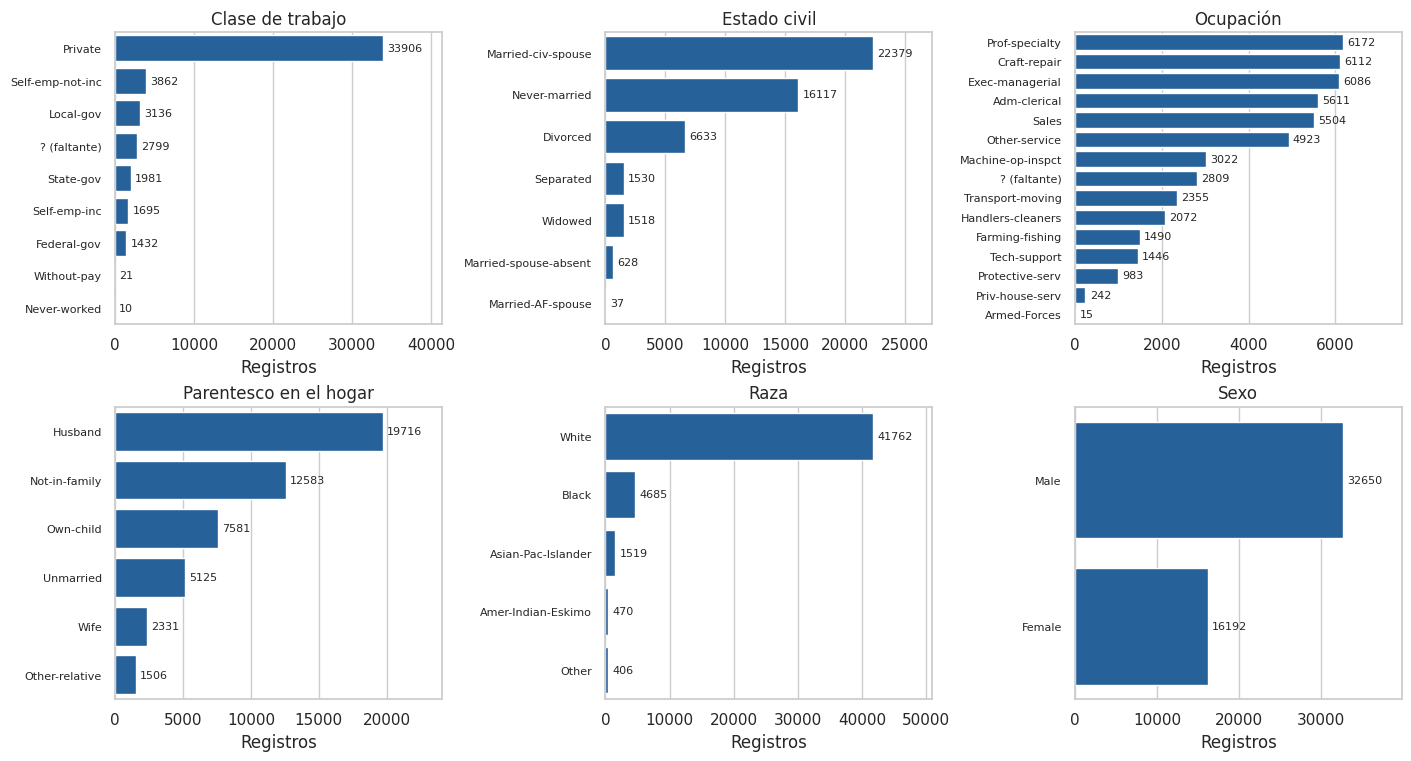

In [13]:
## Se pasa a Pandas una sola vez, solo para graficar
datosCenso = df02.drop("PesoMuestral").toPandas()
rotulos = {
    "ClaseTrabajo": "Clase de trabajo", "EstadoCivil": "Estado civil", "Ocupacion": "Ocupación",
    "Parentesco": "Parentesco en el hogar", "Raza": "Raza", "Sexo": "Sexo",
    "AniosEducacion": "Años de educación",
}

fig, ejes = plt.subplots(2, 3, figsize=(14, 7.5), layout="constrained")
for ax, columna in zip(ejes.flat, categoricas):
    serie = datosCenso[columna].fillna("? (faltante)")
    orden = serie.value_counts().index
    sns.countplot(y=serie, order=orden, color=azul, ax=ax)
    ax.bar_label(ax.containers[0], padding=3, fontsize=8)
    ax.margins(x=0.22)
    ax.set(title=rotulos[columna], xlabel="Registros", ylabel="")
    ax.tick_params(axis="y", labelsize=8)
plt.show()

#### Variables cuantitativas y etiqueta

Edad, años de educación y horas por semana van en histogramas. Las dos clases de `Mas50K` las muestro en barras con el conteo arriba.

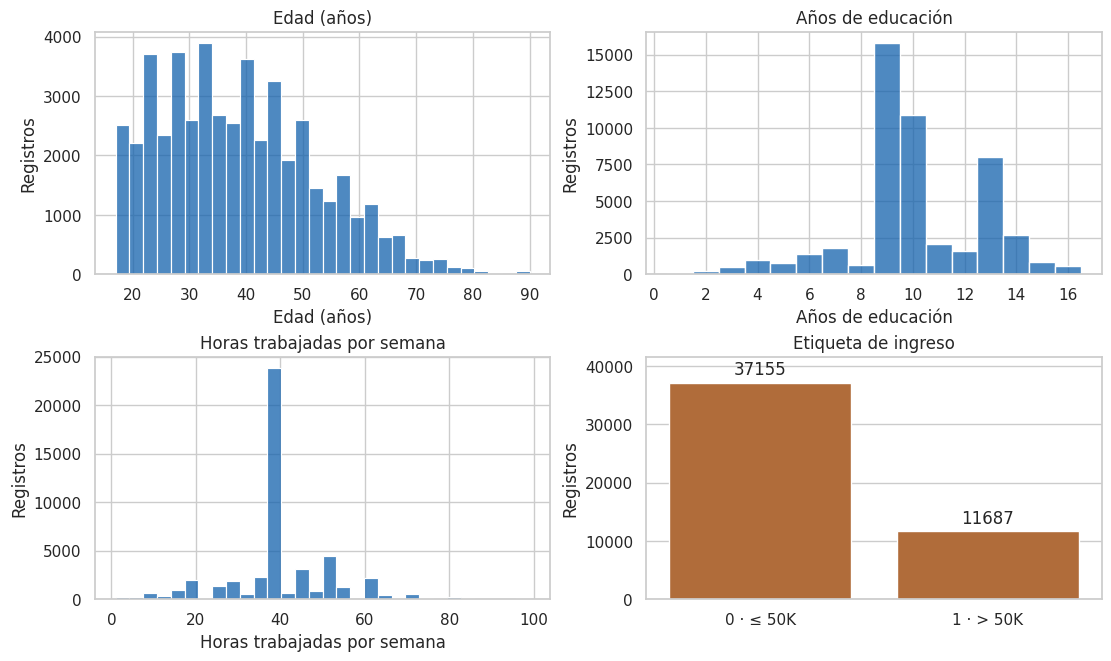

In [14]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 6.5), layout="constrained")
for ax, columna, rotulo in zip(
    ejes.flat, ["Edad", "AniosEducacion", "HorasSemana"],
    ["Edad (años)", "Años de educación", "Horas trabajadas por semana"],
):
    sns.histplot(data=datosCenso, x=columna, bins=16 if columna == "AniosEducacion" else 30,
                 discrete=columna == "AniosEducacion", color=azul, ax=ax)
    ax.set(title=rotulo, xlabel=rotulo, ylabel="Registros")

## Las dos clases de la etiqueta, con el conteo encima de cada barra
ax = ejes[1, 1]
sns.countplot(data=datosCenso, x="Mas50K", order=[0, 1], color=naranja, ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.12)
ax.set(title="Etiqueta de ingreso", xlabel="", ylabel="Registros")
ax.set_xticks([0, 1], ["0 · ≤ 50K", "1 · > 50K"])
plt.show()

La edad tiene una cola hacia la derecha y se concentra entre los 20 y los 50 años. En años de educación sobresalen dos valores, 9 (*HS-grad*) y 10 (*Some-college*). Las horas por semana tienen un pico enorme en **40**, la jornada estándar. La etiqueta tiene **11.687 positivos en 48.842 filas (23,9 %)**: hay desbalance, pero mucho menos extremo que en el ictus.

#### ¿Qué grupos ganan más de 50K?

Para cada categoría calculo el porcentaje de personas con ingreso alto y lo comparo con el promedio global, que es la línea punteada. Dejé por fuera los niveles con menos de 30 registros, porque con tan pocos casos el porcentaje es poco confiable.

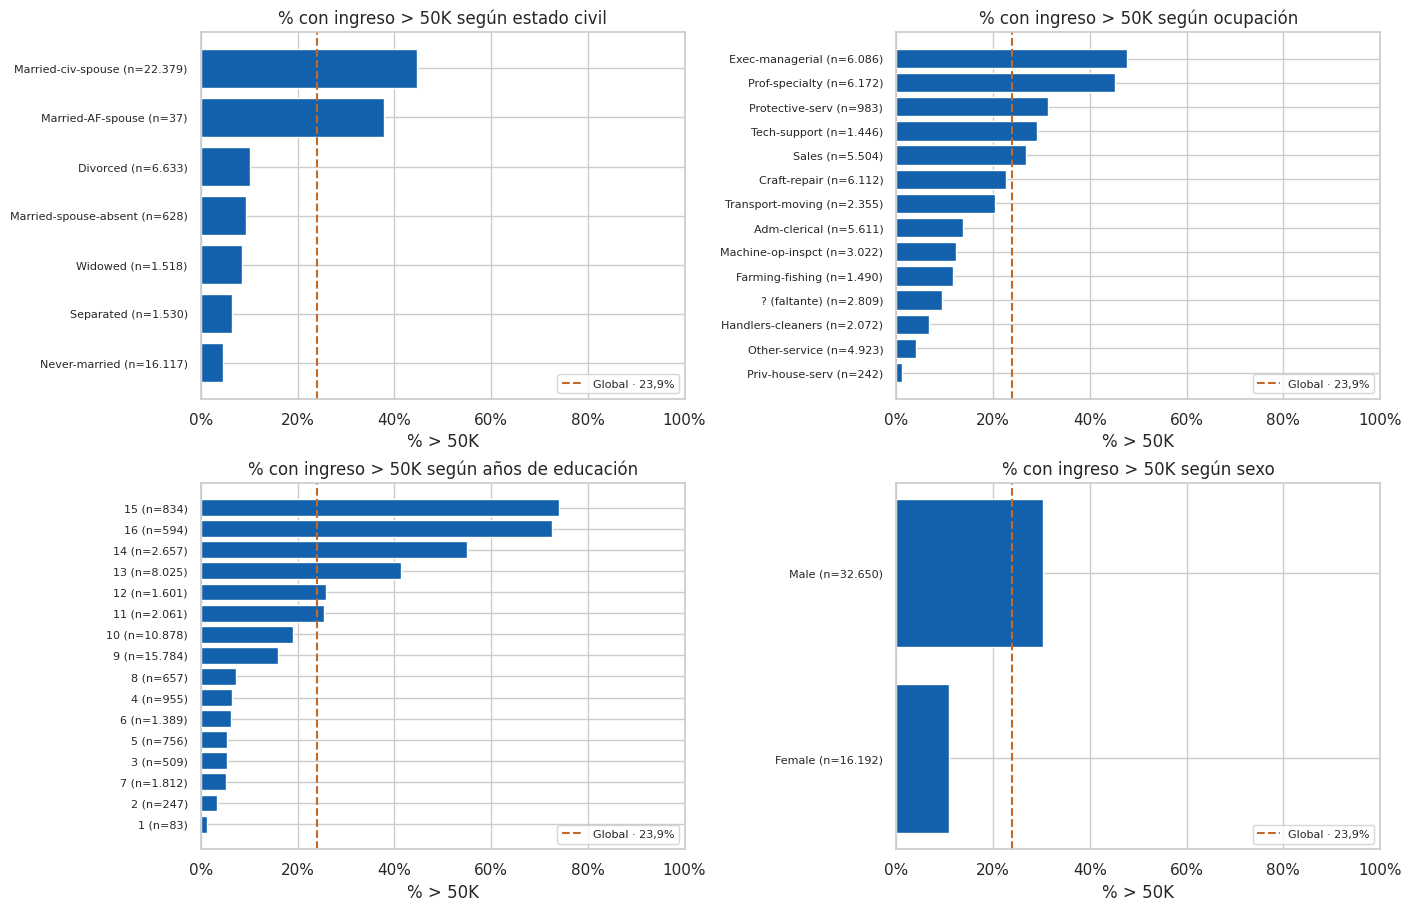

In [15]:
## Porcentaje de ingresos altos en cada categoría, comparado con el promedio global
tasa_global = datosCenso["Mas50K"].mean()


def graficar_tasa(ax, columna, minimo=30):
    """Barras con el % de personas con ingreso > 50K en cada nivel de la columna."""
    tabla = (datosCenso.assign(**{columna: datosCenso[columna].fillna("? (faltante)")})
             .groupby(columna)["Mas50K"].agg(["mean", "size"]))
    tabla = tabla[tabla["size"] >= minimo].sort_values("mean")   # sin niveles de menos de 30 registros
    ax.barh([f"{i} (n={n:,})".replace(",", ".") for i, n in zip(tabla.index, tabla["size"])],
            tabla["mean"], color=azul)
    ax.axvline(tasa_global, ls="--", color=naranja, label=f"Global · {tasa_global:.1%}".replace(".", ","))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=f"% con ingreso > 50K según {rotulos[columna].lower()}", xlabel="% > 50K", xlim=(0, 1))
    ax.tick_params(axis="y", labelsize=8)
    ax.legend(loc="lower right", fontsize=8)


fig, ejes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")
for ax, columna in zip(ejes.flat, ["EstadoCivil", "Ocupacion", "AniosEducacion", "Sexo"]):
    graficar_tasa(ax, columna)
plt.show()

- **Estado civil.** Es el contraste más fuerte. Entre las personas casadas que viven con su cónyuge (`Married-civ-spouse`), el **44,6 %** gana más de 50K. Entre quienes nunca se han casado, apenas el **4,5 %**. Hay que leerlo con cuidado, porque las personas solteras son en promedio más jóvenes.
- **Ocupación.** `Exec-managerial` y `Prof-specialty` están cerca de la mitad, mientras que `Priv-house-serv` y `Other-service` casi no tienen ingresos altos. El grupo sin ocupación reportada también queda muy por debajo del promedio.
- **Educación.** La relación es casi escalonada. Con 9 años (*HS-grad*) el porcentaje es **15,9 %**, con 13 (*Bachelors*) sube a **41,3 %** y con 15 o 16 (*Prof-school* y *Doctorate*) pasa del **72 %**.
- **Sexo.** El **30,4 %** de los hombres gana más de 50K, frente al **10,9 %** de las mujeres. Es una brecha que viene del censo de 1994 y que el modelo va a aprender. La retomo en las conclusiones.

#### Edad, educación y horas según la etiqueta

Como las dos clases tienen tamaños distintos, normalizo cada una por aparte para poder comparar la forma de sus distribuciones. Además calculo la media y la mediana.

Edad         AniosEducacion         HorasSemana        
        Media Mediana          Media Mediana       Media Mediana
Mas50K                                                          
0       36.87    34.0            9.6     9.0       38.84    40.0
1       44.28    43.0           11.6    12.0       45.45    40.0

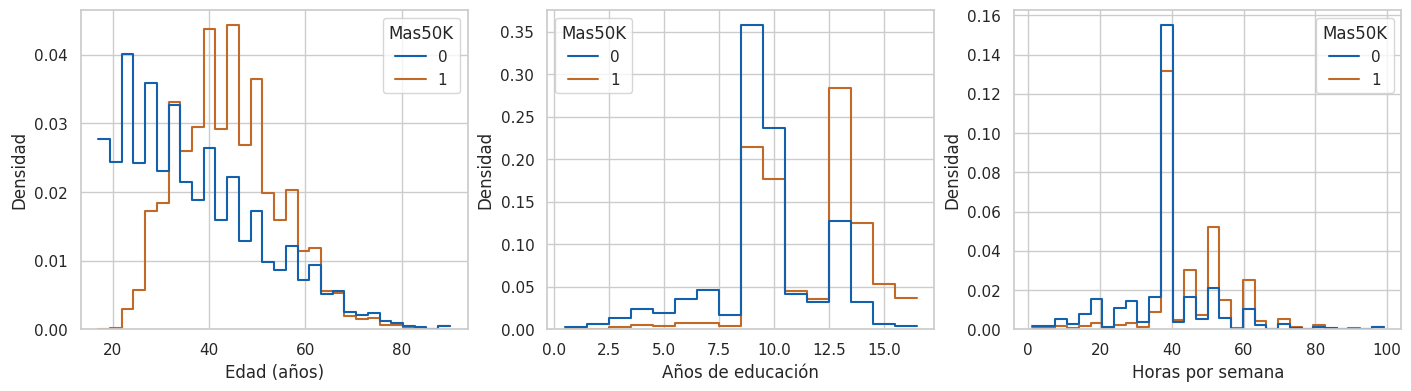

In [16]:
display(datosCenso.groupby("Mas50K")[["Edad", "AniosEducacion", "HorasSemana"]]
        .agg(["mean", "median"]).round(2).rename(columns={"mean": "Media", "median": "Mediana"}))

## Cada clase se normaliza por aparte para comparar la forma de las distribuciones
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8), layout="constrained")
for ax, columna, rotulo in zip(ejes, ["Edad", "AniosEducacion", "HorasSemana"],
                               ["Edad (años)", "Años de educación", "Horas por semana"]):
    sns.histplot(data=datosCenso, x=columna, hue="Mas50K", hue_order=[0, 1],
                 palette={0: azul, 1: naranja}, stat="density", common_norm=False,
                 element="step", fill=False, bins=16 if columna == "AniosEducacion" else 30,
                 discrete=columna == "AniosEducacion", ax=ax)
    ax.set(xlabel=rotulo, ylabel="Densidad")
plt.show()

Las personas con ingreso alto son mayores (mediana de **43 frente a 34 años**) y estudiaron más (mediana de **12 frente a 9 años**). En horas por semana la mediana es 40 en los dos grupos, pero la media sube de **38,84 a 45,45**, porque quienes ganan más de 50K trabajan con más frecuencia jornadas largas. Aun así, en las tres variables las dos clases se superponen bastante.

#### Correlación entre las variables numéricas

Como en las guías, cierro la exploración con la matriz de correlación de las variables numéricas y la etiqueta.

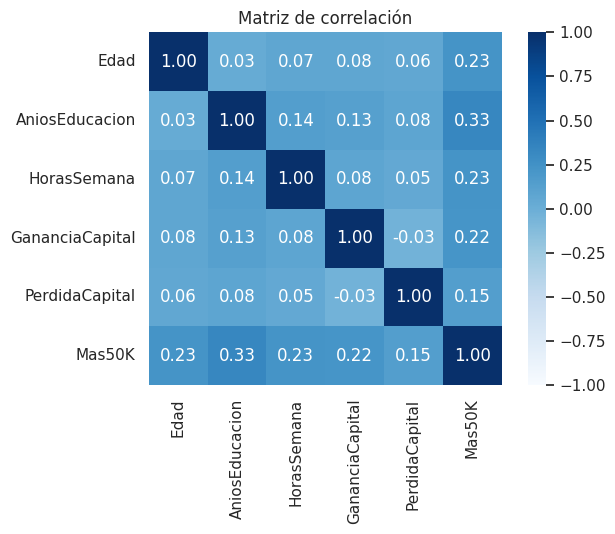

In [17]:
## Correlación lineal entre las variables numéricas y la etiqueta
correlacion = datosCenso[["Edad", "AniosEducacion", "HorasSemana", "GananciaCapital",
                          "PerdidaCapital", "Mas50K"]].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

Las correlaciones con `Mas50K` son todas moderadas o bajas: **años de educación 0,33**, edad 0,23, horas por semana 0,23, ganancia de capital 0,22 y pérdida de capital 0,15. Ninguna variable separa las clases por sí sola. Entre las variables de entrada las correlaciones son todavía más bajas (la mayor es 0,14), así que no hay dos numéricas que digan lo mismo.

### 2. Preparación de datos

#### Faltantes, país de origen y columnas que salen

Tomé estas decisiones y las aplico en `df03`:

- **Faltantes como categoría.** En lugar de borrar las 3.620 filas con `?`, reemplazo los nulos de `ClaseTrabajo` y `Ocupacion` por `Desconocido`, igual que hice con `Unknown` en el ictus. En la gráfica de ocupación se vio que ese grupo tiene un porcentaje propio de ingresos altos, así que el faltante también es información.

**¿Por qué no imputar con la moda?** La otra opción habitual, y la que usa la GUIA02, es rellenar los `?` con el valor más frecuente de cada columna (por ejemplo `Private` en la clase de trabajo). La descarté a propósito. Imputar por la moda tiene sentido cuando el dato falta al azar, pero aquí no es el caso: el faltante se concentra en personas sin empleo o fuera del mercado laboral y está asociado a un ingreso bajo, como se ve en la gráfica de ocupación. Rellenar con la moda metería a ese grupo en la categoría mayoritaria y borraría esa señal. Por eso conservo el faltante como una categoría propia, que es lo que el modelo puede aprovechar.
- **País agrupado en `RegionOrigen`.** Dejo `United-States` y `Mexico`, que tienen tamaño suficiente, junto `Otro` para los demás países y `Desconocido` para los `?`. Así evito 40 columnas casi vacías y el caso de `Holand-Netherlands`, que tiene un solo registro.
- **Columnas que quito.** `PesoMuestral`, porque no describe a la persona. `Educacion`, porque repite a `AniosEducacion`. `PaisOrigen`, porque queda reemplazada por `RegionOrigen`. E `Ingreso`, porque la etiqueta ya está en `Mas50K`.

In [18]:
## País de origen agrupado en cuatro niveles
region = (F.when(F.col("PaisOrigen").isNull(), "Desconocido")
          .when(F.col("PaisOrigen").isin("United-States", "Mexico"), F.col("PaisOrigen"))
          .otherwise("Otro"))

df03 = (df02.fillna({"ClaseTrabajo": "Desconocido", "Ocupacion": "Desconocido"})   # faltantes como categoría
        .withColumn("RegionOrigen", region)
        .drop("PesoMuestral", "Educacion", "PaisOrigen", "Ingreso"))             # columnas que no uso

df03.groupBy("RegionOrigen").agg(
    F.count("*").alias("Registros"),
    F.round(100 * F.avg("Mas50K"), 1).alias("% > 50K"),
).orderBy(F.desc("Registros")).show()

## Verificación: no debe quedar ningún nulo
df03.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df03.columns]).show()

+-------------+---------+-------+
| RegionOrigen|Registros|% > 50K|
+-------------+---------+-------+
|United-States|    43832|   24.4|
|         Otro|     3202|   22.7|
|       Mexico|      951|    4.9|
|  Desconocido|      857|   25.7|
+-------------+---------+-------+

+----+------------+--------------+-----------+---------+----------+----+----+---------------+--------------+-----------+--------+------+------------+
|Edad|ClaseTrabajo|AniosEducacion|EstadoCivil|Ocupacion|Parentesco|Raza|Sexo|GananciaCapital|PerdidaCapital|HorasSemana|Conjunto|Mas50K|RegionOrigen|
+----+------------+--------------+-----------+---------+----------+----+----+---------------+--------------+-----------+--------+------+------------+
|   0|           0|             0|          0|        0|         0|   0|   0|              0|             0|          0|       0|     0|           0|
+----+------------+--------------+-----------+---------+----------+----+----+---------------+--------------+-----------+-------

Al agrupar el país apareció algo que no esperaba. Solo el **4,9 %** de las personas de origen mexicano gana más de 50K, frente al **24,4 %** de las nacidas en Estados Unidos y el **22,7 %** del resto de países. Por eso valió la pena dejar a México como grupo aparte. La segunda tabla confirma que ya no queda ningún nulo.

#### Gráficas de la preparación

Para cerrar esta sección con lo visual, muestro dos decisiones que acabo de tomar: a la izquierda, los faltantes que conservo como categoría; a la derecha, el porcentaje de ingreso alto en cada nivel de `RegionOrigen`, que es lo que justifica dejar a México como grupo aparte.

In [ ]:
## Dos gráficas que ilustran las decisiones de preparación
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")

## Izquierda: faltantes por columna, antes de tratarlos (sobre df02)
faltantes = (df02.select([F.count(F.when(F.col(c).isNull(), c)).alias(c)
                          for c in ["ClaseTrabajo", "Ocupacion", "PaisOrigen"]])
             .toPandas().T[0].sort_values())
ax1.barh(faltantes.index, faltantes.values, color=azul)
ax1.bar_label(ax1.containers[0], labels=[f"{v:,}".replace(",", ".") for v in faltantes.values], padding=3)
ax1.margins(x=0.18)
ax1.set(title="Valores faltantes por columna (antes de tratarlos)", xlabel="Registros con ?")

## Derecha: % de ingreso > 50K según la región de origen agrupada (sobre df03)
region = (df03.groupBy("RegionOrigen")
          .agg((100 * F.avg("Mas50K")).alias("tasa"), F.count("*").alias("n"))
          .orderBy("tasa").toPandas())
ax2.barh([f"{r} (n={n:,})".replace(",", ".") for r, n in zip(region["RegionOrigen"], region["n"])],
         region["tasa"], color=naranja)
ax2.bar_label(ax2.containers[0], labels=[f"{v:.1f} %".replace(".", ",") for v in region["tasa"]], padding=3)
ax2.margins(x=0.20)
ax2.set(title="% con ingreso > 50K según región de origen", xlabel="% > 50K")

plt.show()

La gráfica de la izquierda muestra que el problema de faltantes se concentra en `ClaseTrabajo` y `Ocupacion` (casi 2.800 registros cada una), mucho más que en el país. La de la derecha confirma la decisión del agrupamiento: México tiene una tasa de ingreso alto del 4,9 %, muy por debajo de Estados Unidos (24,4 %) y del resto de países (22,7 %), así que mantenerlo separado le da al modelo una señal que se perdería si lo juntara todo en `Otro`. El grupo `Desconocido` queda cerca del promedio, lo que muestra que el faltante del país, a diferencia del de la ocupación, no cambia mucho la tasa.

#### Separación de entrenamiento y prueba

Uso la partición que trae el dataset: `adult.data` para entrenar y `adult.test` para evaluar. Los autores la armaron al azar, con dos tercios y un tercio de los registros. Usarla me permite comparar mis resultados con los errores de referencia que publican en `adult.names`. La proporción de positivos es casi la misma en los dos conjuntos.

In [19]:
## Reconstruyo la partición original (adult.data / adult.test) y reviso el balance de clases
semilla = 42
entrenamiento_limpio = df03.filter(F.col("Conjunto") == "Entrenamiento").drop("Conjunto")
prueba_limpia = df03.filter(F.col("Conjunto") == "Prueba").drop("Conjunto")

for nombre, datos in [("Entrenamiento", entrenamiento_limpio), ("Prueba", prueba_limpia)]:
    n = datos.count()
    positivos = datos.filter(F.col("Mas50K") == 1).count()
    print(f"{nombre:14s}: {n:,} registros, {positivos:,} con ingreso > 50K ({positivos / n:.2%})")

Entrenamiento : 32,561 registros, 7,841 con ingreso > 50K (24.08%)
Prueba        : 16,281 registros, 3,846 con ingreso > 50K (23.62%)


#### Pesos por clase

Aunque el desbalance aquí es moderado, quiero medir qué pasa cuando los errores sobre la clase alta cuestan más. Para eso calculo un peso por clase con la misma fórmula del taller de Stroke: el total de filas dividido entre dos veces las filas de esa clase. La columna `peso` solo la usan los modelos de la segunda ronda de entrenamiento, en la sección 4.

In [20]:
## Peso de cada clase: inversamente proporcional a su frecuencia en entrenamiento
n = entrenamiento_limpio.count()
nPos = entrenamiento_limpio.filter(F.col("Mas50K") == 1).count()
nNeg = n - nPos
pesoPos, pesoNeg = n / (2.0 * nPos), n / (2.0 * nNeg)
print(f"Peso de la clase 1 (> 50K): {pesoPos:.3f}")
print(f"Peso de la clase 0 (≤ 50K): {pesoNeg:.3f}")

entrenamiento_limpio = entrenamiento_limpio.withColumn(
    "peso", F.when(F.col("Mas50K") == 1, pesoPos).otherwise(pesoNeg))

Peso de la clase 1 (> 50K): 2.076
Peso de la clase 0 (≤ 50K): 0.659


Cada persona con ingreso alto pesa **2,076** y cada una con ingreso bajo **0,659**, es decir, unas tres veces menos.

#### Categorías y vector de entrada

`StringIndexer` convierte cada categoría en un índice numérico, y luego `OneHotEncoder` transforma ese índice en columnas indicadoras. Lo hago así porque el índice de `Sales` o de `Husband` es solo un código y no implica ningún orden. Con `VectorAssembler` reúno las cinco variables numéricas y los indicadores, y `StandardScaler` deja todas las posiciones en una escala comparable. Esto último importa aquí porque la ganancia de capital llega a 99.999 y los indicadores valen 0 o 1. El resultado es la columna `independientes`, con **53 posiciones**. `Mas50K` se queda aparte como etiqueta.

**Tip.** El pipeline se ajusta con `fit()` usando solo entrenamiento, y ese mismo modelo se aplica con `transform()` a los dos conjuntos. Así, ni los códigos de las categorías ni las desviaciones del escalador se calculan con datos de prueba. Con `handleInvalid="keep"`, una categoría que aparezca solo en la prueba va a una posición reservada en lugar de producir un error.

In [21]:
categoricas_modelo = ["ClaseTrabajo", "EstadoCivil", "Ocupacion", "Parentesco", "Raza", "Sexo", "RegionOrigen"]
numericas = ["Edad", "AniosEducacion", "HorasSemana", "GananciaCapital", "PerdidaCapital"]
indices = [f"{columna}_IND" for columna in categoricas_modelo]
indicadores = [f"{columna}_OHE" for columna in categoricas_modelo]

## Etapas de preparación
indexadores = [StringIndexer(inputCol=columna, outputCol=indice, handleInvalid="keep")
               for columna, indice in zip(categoricas_modelo, indices)]
codificador = OneHotEncoder(inputCols=indices, outputCols=indicadores)
ensamblador = VectorAssembler(inputCols=numericas + indicadores, outputCol="sin_escalar")
escalador = StandardScaler(inputCol="sin_escalar", outputCol="independientes")

## El pipeline se ajusta solo con entrenamiento y se aplica a los dos conjuntos
pipeline = Pipeline(stages=indexadores + [codificador, ensamblador, escalador]).fit(entrenamiento_limpio)
df04 = pipeline.transform(entrenamiento_limpio)
entrenamiento = df04.select("independientes", "Mas50K", "peso").cache()
prueba = pipeline.transform(prueba_limpia).select("independientes", "Mas50K").cache()

## Nombre de cada posición del vector, tomado de los metadatos que deja el VectorAssembler
meta = df04.schema["sin_escalar"].metadata["ml_attr"]["attrs"]
nombres_vector = [nombre for _, nombre in sorted((a["idx"], a["name"]) for grupo in meta.values() for a in grupo)]

print(f"Entrenamiento: {entrenamiento.count():,} filas · Prueba: {prueba.count():,} filas")
print("Dimensión del vector de entrada:", len(nombres_vector))
entrenamiento.select("independientes", "Mas50K").show(3, truncate=90)

Entrenamiento: 32,561 filas · Prueba: 16,281 filas
Dimensión del vector de entrada: 53
+------------------------------------------------------------------------------------------+------+
|                                                                            independientes|Mas50K|
+------------------------------------------------------------------------------------------+------+
|(53,[0,1,2,3,9,15,24,37,42,47,49],[2.8591468669928934,5.053017165512665,3.2395408818340...|     0|
|(53,[0,1,2,6,14,23,36,42,47,49],[3.6655729064011453,5.053017165512665,1.052850786596050...|     0|
|(53,[0,1,2,5,16,30,37,42,47,49],[2.7858354088648705,3.49824265304723,3.2395408818340017...|     0|
+------------------------------------------------------------------------------------------+------+
only showing top 3 rows



### 3. Selección de modelos de MLlib

La guía pide al menos cinco modelos. Elegí **ocho** para cubrir familias distintas: los tres del tutorial de Spark, los cuatro que agrega la guía de clasificación y el perceptrón que ya había usado en el cuaderno ICTUS.

| Modelo | Cómo usa las variables |
| --- | --- |
| Regresión logística | Hace una combinación lineal de las variables y la convierte en la probabilidad de la clase 1. |
| Árbol de decisión | Va partiendo los datos con preguntas sucesivas sobre las variables, hasta 6 niveles. |
| Bosque aleatorio | Reúne 60 árboles, cada uno entrenado con una muestra y un subconjunto de variables diferentes. |
| *Gradient boosting* (GBT) | Construye 60 árboles en secuencia, y cada uno corrige los errores que dejaron los anteriores. |
| SVM lineal | Busca la frontera con mayor margen y da una puntuación que indica de qué lado queda cada fila. |
| Naive Bayes | Supone que las variables son independientes entre sí y combina la evidencia de cada una. Uso la versión gaussiana. |
| Máquina de factorización | Es un modelo lineal al que se le agregan interacciones entre pares de variables, resumidas en pocos factores. |
| Perceptrón multicapa | Aprende combinaciones de las entradas a través de una capa oculta de 16 neuronas. |

Los ocho parten exactamente del mismo vector de entrada. Usé configuraciones sencillas y dejé el umbral de clasificación que trae cada algoritmo por defecto. La función `crear_modelos` devuelve el diccionario de clasificadores, y `entrenar` ajusta cada uno, predice sobre la prueba y mide el tiempo. Las definí como funciones porque en la sección 4 las vuelvo a usar con pesos. [Clasificadores de Spark ML](https://spark.apache.org/docs/3.5.5/ml-classification-regression.html)

In [22]:
## Defino los ocho clasificadores y una función para entrenarlos y predecir sobre la prueba
dimension = len(nombres_vector)
opciones = dict(labelCol="Mas50K", featuresCol="independientes")


def crear_modelos(con_pesos=False):
    """Diccionario con los clasificadores. Con pesos solo van los que aceptan weightCol."""
    w = {"weightCol": "peso"} if con_pesos else {}
    modelos = {
        "Regresión logística": LogisticRegression(maxIter=100, **opciones, **w),
        "Árbol de decisión": DecisionTreeClassifier(maxDepth=6, seed=semilla, **opciones, **w),
        "Bosque aleatorio": RandomForestClassifier(numTrees=60, maxDepth=8, seed=semilla, **opciones, **w),
        "Gradient boosting": GBTClassifier(maxIter=60, maxDepth=5, seed=semilla, **opciones, **w),
        "SVM lineal": LinearSVC(maxIter=100, regParam=0.01, **opciones, **w),
        "Naive Bayes": NaiveBayes(modelType="gaussian", **opciones, **w),
    }
    if not con_pesos:
        modelos["Máquina de factorización"] = FMClassifier(factorSize=4, stepSize=0.01, maxIter=100,
                                                           seed=semilla, **opciones)
        modelos["Perceptrón multicapa"] = MultilayerPerceptronClassifier(
            layers=[dimension, 16, 2], maxIter=200, seed=semilla, **opciones)
    return modelos


def entrenar(modelos):
    """Entrena cada clasificador, predice sobre la prueba y guarda el tiempo de ajuste."""
    ajustados, salidas, tiempos = {}, {}, {}
    for nombre, clasificador in modelos.items():
        inicio = time.perf_counter()
        ajustados[nombre] = clasificador.fit(entrenamiento)        # entrena el modelo
        tiempos[nombre] = time.perf_counter() - inicio
        salidas[nombre] = ajustados[nombre].transform(prueba).cache()   # predicciones sobre la prueba
        print(f"{nombre}: entrenado en {tiempos[nombre]:.1f} s")
    return ajustados, salidas, tiempos


modelos = crear_modelos()
ajustados, salidas, tiempos = entrenar(modelos)
salidas["Gradient boosting"].select("Mas50K", "rawPrediction", "probability", "prediction").show(5, truncate=45)

Regresión logística: entrenado en 4.3 s
Árbol de decisión: entrenado en 1.4 s


Bosque aleatorio: entrenado en 5.0 s
Gradient boosting: entrenado en 30.5 s
SVM lineal: entrenado en 12.8 s
Naive Bayes: entrenado en 0.6 s


Máquina de factorización: entrenado en 11.9 s
Perceptrón multicapa: entrenado en 22.0 s
+------+----------------------------------------+-----------------------------------------+----------+
|Mas50K|                           rawPrediction|                              probability|prediction|
+------+----------------------------------------+-----------------------------------------+----------+
|     0|  [1.957145897324866,-1.957145897324866]| [0.9804357231482103,0.01956427685178974]|       0.0|
|     0|[0.5893755258207511,-0.5893755258207511]| [0.7647231652200353,0.23527683477996475]|       0.0|
|     1|[0.5072930243258785,-0.5072930243258785]|  [0.7339166866951008,0.2660833133048992]|       0.0|
|     1|[-1.7558768532249434,1.7558768532249434]|[0.028979646056833352,0.9710203539431667]|       1.0|
|     0|    [1.97544067807389,-1.97544067807389]|[0.9811253662755226,0.018874633724477397]|       0.0|
+------+----------------------------------------+---------------------------------------

La tabla muestra las columnas que agrega un modelo de MLlib al predecir. `rawPrediction` es el puntaje sin transformar, `probability` es la probabilidad de cada clase y `prediction` es la clase elegida.

### 4. Evaluación de modelos

Como punto de referencia armé una línea base que predice 0 para todas las filas. Con 23,6 % de positivos en la prueba, esa regla ya acierta en el 76,4 % de los casos. Por eso, además de la exactitud, miro cuántas personas con ingreso alto encuentra cada modelo.

- **Exactitud** mide la fracción de filas clasificadas correctamente.
- **Precisión de la clase 1** indica, de las filas que el modelo marcó con 1, cuántas eran positivos reales.
- **Recall o sensibilidad** indica, de los positivos reales, cuántos encontró el modelo. **F1** resume precisión y recall en un solo número.
- **ROC AUC y AUC PR** evalúan el orden que genera el puntaje a medida que se mueve el umbral. El AUC PR es el área bajo la curva de precisión–recall y lo contrasto con la proporción de positivos.

Las cuatro primeras las calculo con `MulticlassClassificationEvaluator` y las dos últimas con `BinaryClassificationEvaluator`, los dos evaluadores de MLlib. Para las áreas necesito un puntaje por fila. Uso la probabilidad de la clase 1, y en la SVM, que no entrega probabilidad, el margen. El ejemplo muestra cómo `vector_to_array` saca ese puntaje del vector.

In [23]:
## Ejemplo: vector_to_array convierte el vector de probabilidad en una lista; la posición [1] es la clase 1
(salidas["Gradient boosting"]
 .select("probability", vector_to_array("probability")[1].alias("Puntaje"), "prediction", "Mas50K")
 .show(3, truncate=False))

+----------------------------------------+-------------------+----------+------+
|probability                             |Puntaje            |prediction|Mas50K|
+----------------------------------------+-------------------+----------+------+
|[0.9804357231482103,0.01956427685178974]|0.01956427685178974|0.0       |0     |
|[0.7647231652200353,0.23527683477996475]|0.23527683477996475|0.0       |0     |
|[0.7339166866951008,0.2660833133048992] |0.2660833133048992 |0.0       |1     |
+----------------------------------------+-------------------+----------+------+
only showing top 3 rows



In [24]:
## Evaluadores de MLlib
def evaluador(metrica, etiqueta=None):
    e = MulticlassClassificationEvaluator(labelCol="Mas50K", predictionCol="prediction", metricName=metrica)
    return e.setMetricLabel(etiqueta) if etiqueta is not None else e


evExactitud = evaluador("accuracy")
evPrecision1 = evaluador("precisionByLabel", 1.0)
evRecall1 = evaluador("recallByLabel", 1.0)
evF1 = evaluador("fMeasureByLabel", 1.0)


def medir(salida):
    """Métricas de un modelo sobre la prueba y sus puntajes en Pandas para las curvas."""
    ## Puntaje: la probabilidad de la clase 1, o el margen cuando el modelo no da probabilidad (SVM)
    columna_score = "probability" if "probability" in salida.columns else "rawPrediction"
    evROC = BinaryClassificationEvaluator(labelCol="Mas50K", rawPredictionCol=columna_score, metricName="areaUnderROC")
    evPR = BinaryClassificationEvaluator(labelCol="Mas50K", rawPredictionCol=columna_score, metricName="areaUnderPR")
    tabla = salida.select("Mas50K", "prediction", vector_to_array(columna_score)[1].alias("Puntaje")).toPandas()
    matriz = confusion_matrix(tabla["Mas50K"], tabla["prediction"], labels=[0, 1])
    vn, fp, fn, vp = matriz.ravel()
    fila = {
        "Exactitud": evExactitud.evaluate(salida),
        "Precisión (1)": evPrecision1.evaluate(salida) if vp + fp > 0 else 0.0,
        "Recall (1)": evRecall1.evaluate(salida),
        "F1 (1)": evF1.evaluate(salida),
        "ROC AUC": evROC.evaluate(salida),
        "AUC PR": evPR.evaluate(salida),
        "FP": fp, "FN": fn, "VP": vp,
    }
    return fila, matriz, tabla


filas, matrices, predicciones = [], {}, {}
for nombre, salida in salidas.items():
    fila, matrices[nombre], predicciones[nombre] = medir(salida)
    filas.append({"Modelo": nombre, **fila, "Segundos": tiempos[nombre]})

## Línea base: predecir 0 (≤ 50K) para todas las filas
nombre_base = "Base · todo 0"
etiquetas = predicciones["Regresión logística"]["Mas50K"]
matrices[nombre_base] = confusion_matrix(etiquetas, np.zeros(len(etiquetas)), labels=[0, 1])
filas.append({"Modelo": nombre_base, "Exactitud": 1 - etiquetas.mean(), "Precisión (1)": 0.0, "Recall (1)": 0.0,
              "F1 (1)": 0.0, "ROC AUC": 0.5, "AUC PR": etiquetas.mean(),
              "FP": 0, "FN": int(etiquetas.sum()), "VP": 0, "Segundos": 0.0})

resultados = pd.DataFrame(filas).set_index("Modelo")
display(resultados.sort_values("ROC AUC", ascending=False).round(3))

,Exactitud,Precisión (1),Recall (1),F1 (1),ROC AUC,AUC PR,FP,FN,VP,Segundos
Modelo,,,,,,,,,,
Gradient boosting,0.861,0.748,0.624,0.680,0.913,0.786,809,1447,2399,30.471
Perceptrón multicapa,0.856,0.725,0.629,0.674,0.907,0.773,916,1427,2419,21.954
Regresión logística,0.853,0.729,0.600,0.658,0.904,0.762,858,1538,2308,4.297
Bosque aleatorio,0.851,0.794,0.499,0.613,0.903,0.767,499,1926,1920,5.016
Máquina de factorización,0.853,0.732,0.594,0.656,0.903,0.759,836,1560,2286,11.895
SVM lineal,0.853,0.735,0.587,0.653,0.901,0.754,814,1587,2259,12.828
Árbol de decisión,0.847,0.778,0.490,0.602,0.879,0.737,538,1960,1886,1.375
Naive Bayes,0.585,0.357,0.944,0.518,0.855,0.596,6544,216,3630,0.636
Base · todo 0,0.764,0.000,0.000,0.000,0.500,0.236,0,3846,0,0.000


#### Matrices de confusión

Las filas corresponden a la clase real y las columnas a la predicción. Los números son conteos y el color indica la proporción dentro de la fila. La casilla de abajo a la izquierda son los falsos negativos (FN): personas que ganan más de 50K y que el modelo no reconoció.

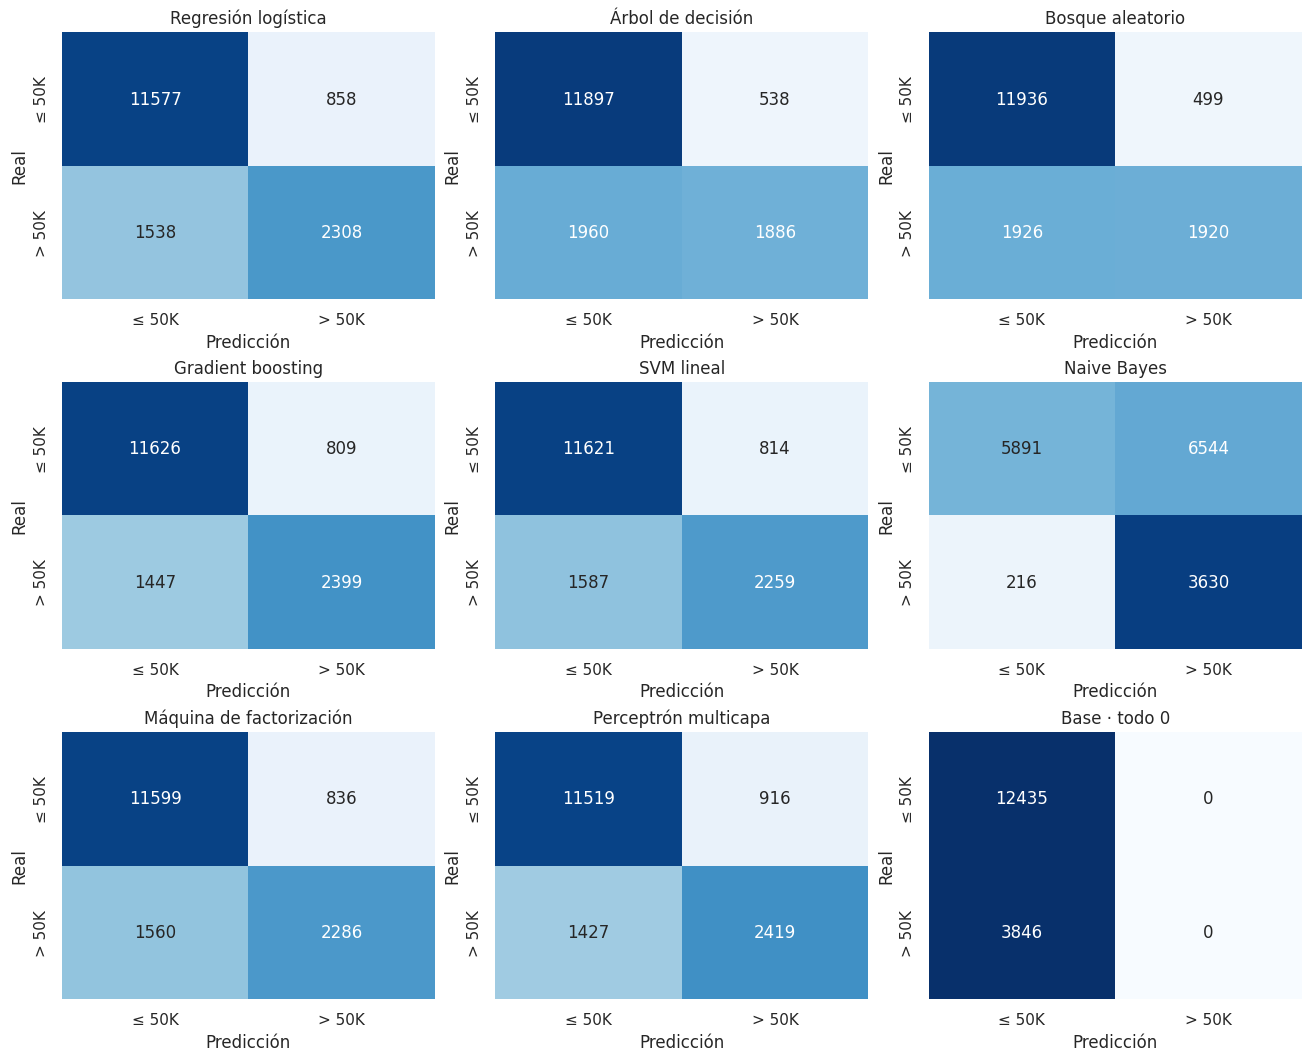

In [25]:
## Matriz de confusión de cada modelo: el conteo es el número y la proporción por fila es el color
fig, ejes = plt.subplots(3, 3, figsize=(13, 10.5), layout="constrained")
for ax, (nombre, matriz) in zip(ejes.flat, matrices.items()):
    proporcion = matriz / matriz.sum(axis=1, keepdims=True)    # el color es la proporción dentro de la fila
    sns.heatmap(proporcion, annot=matriz, fmt="d", cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=["≤ 50K", "> 50K"], yticklabels=["≤ 50K", "> 50K"], ax=ax)
    ax.set(title=nombre, xlabel="Predicción", ylabel="Real")
plt.show()

Siete de los ocho modelos se parecen. Aciertan casi siempre con la clase baja y se equivocan bastante más con la alta. El árbol y el bosque son los más conservadores: producen pocos falsos positivos (538 y 499), pero dejan escapar cerca de la mitad de las personas con ingreso alto. El GBT y el perceptrón encuentran unas 2.400 de las 3.846.

**Naive Bayes** se comporta al revés. Marca como ingreso alto a más de la mitad de la prueba, encuentra 3.630 de los 3.846 positivos y produce **6.544 falsos positivos**. Por eso su exactitud (58,5 %) queda incluso por debajo de la línea base.

#### Comparación gráfica de los modelos

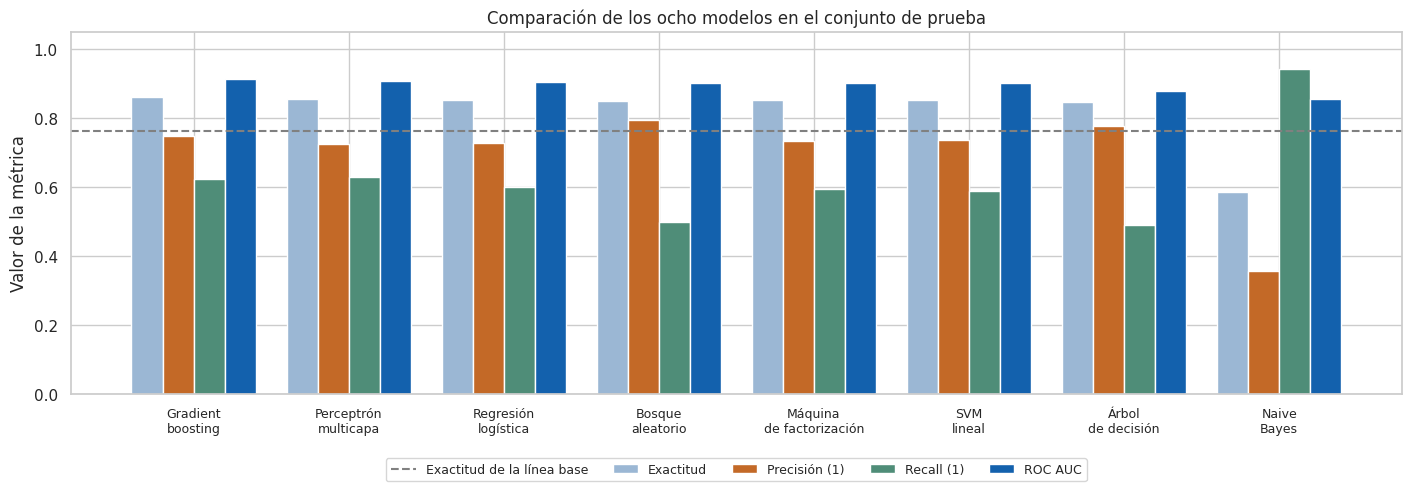

In [26]:
## Cuatro métricas por modelo, ordenadas por ROC AUC
grafica = resultados.drop(index=nombre_base).sort_values("ROC AUC", ascending=False)
metricas = ["Exactitud", "Precisión (1)", "Recall (1)", "ROC AUC"]
colores = ["#9bb7d4", naranja, "#4f8d78", azul]
ancho = 0.2
x = np.arange(len(grafica))

fig, ax = plt.subplots(figsize=(14, 4.8), layout="constrained")
for i, (metrica, color) in enumerate(zip(metricas, colores)):
    ax.bar(x + (i - 1.5) * ancho, grafica[metrica], ancho, label=metrica, color=color)
ax.axhline(resultados.loc[nombre_base, "Exactitud"], ls="--", color="gray", label="Exactitud de la línea base")
ax.set_xticks(x, [n.replace(" ", "\n", 1) for n in grafica.index], fontsize=9)
ax.set(ylim=(0, 1.05), ylabel="Valor de la métrica", title="Comparación de los ocho modelos en el conjunto de prueba")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=9)
plt.show()

#### Curvas ROC y precisión–recall

Las curvas salen de los puntajes del conjunto de **prueba**. En la ROC, la diagonal representa un orden que no discrimina. En precisión–recall, la línea de referencia es el porcentaje de positivos en prueba.

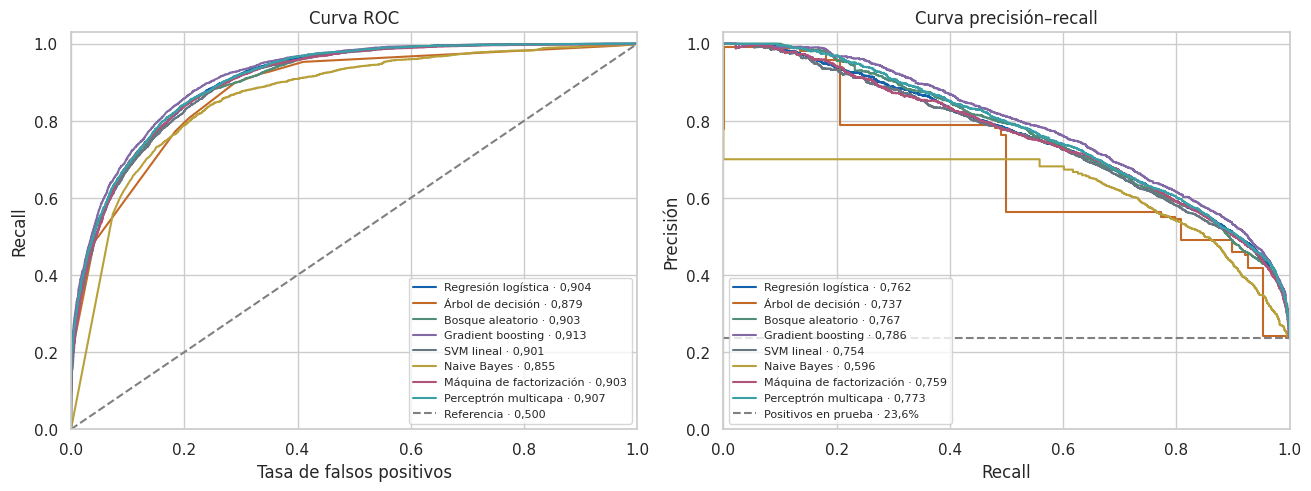

In [27]:
## Curvas ROC y precisión–recall de los ocho modelos sobre la prueba
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for color, nombre in zip(paleta, modelos):
    tabla = predicciones[nombre]
    fpr, tpr, _ = roc_curve(tabla["Mas50K"], tabla["Puntaje"])
    precision, recall, _ = precision_recall_curve(tabla["Mas50K"], tabla["Puntaje"])
    ax_roc.plot(fpr, tpr, color=color, label=f"{nombre} · {resultados.loc[nombre, 'ROC AUC']:.3f}".replace(".", ","))
    ax_pr.step(recall, precision, where="post", color=color,
               label=f"{nombre} · {resultados.loc[nombre, 'AUC PR']:.3f}".replace(".", ","))

ax_roc.plot([0, 1], [0, 1], "--", color="gray", label="Referencia · 0,500")
ax_pr.axhline(etiquetas.mean(), ls="--", color="gray",
              label=f"Positivos en prueba · {etiquetas.mean():.1%}".replace(".", ","))
ax_roc.set(title="Curva ROC", xlabel="Tasa de falsos positivos", ylabel="Recall")
ax_pr.set(title="Curva precisión–recall", xlabel="Recall", ylabel="Precisión")
for ax in (ax_roc, ax_pr):
    ax.set(xlim=(0, 1), ylim=(0, 1.03))
    ax.legend(loc="best", fontsize=8)
plt.show()

Seis curvas van casi pegadas, con el GBT un poco por encima en todo el recorrido. El árbol de decisión queda por debajo y avanza a saltos, porque solo produce tantos puntajes distintos como hojas tiene. Naive Bayes es el más bajo en las dos gráficas. En precisión–recall se ve el costo de buscar más positivos: para pasar de 60 % a 80 % de recall, la precisión del GBT cae de cerca de 0,75 a poco más de 0,60.

#### Manejo del desbalance con pesos

Con el umbral por defecto, los mejores modelos encuentran cerca del 60 % de las personas con ingreso alto. Para subir ese número vuelvo a entrenar con la columna `peso`, como en el taller de Stroke. Solo entran los seis clasificadores que aceptan `weightCol`. La máquina de factorización y el perceptrón multicapa no tienen ese parámetro en MLlib.

In [28]:
## Los seis clasificadores que aceptan weightCol, ahora entrenados con el peso de cada clase
modelos_pesos = crear_modelos(con_pesos=True)
ajustados_pesos, salidas_pesos, tiempos_pesos = entrenar(modelos_pesos)

filas_pesos = []
for nombre, salida in salidas_pesos.items():
    fila, matriz, _ = medir(salida)
    filas_pesos.append({"Modelo": nombre, "Variante": "Con pesos", **fila})
    filas_pesos.append({"Modelo": nombre, "Variante": "Sin pesos", **resultados.loc[nombre].drop("Segundos")})

comparacion = (pd.DataFrame(filas_pesos).set_index(["Modelo", "Variante"]).sort_index()
               .astype({"FP": int, "FN": int, "VP": int}))
display(comparacion.round(3))

Regresión logística: entrenado en 2.9 s
Árbol de decisión: entrenado en 0.8 s


Bosque aleatorio: entrenado en 4.7 s
Gradient boosting: entrenado en 31.6 s
SVM lineal: entrenado en 10.3 s
Naive Bayes: entrenado en 0.2 s


Exactitud  Precisión (1)  Recall (1)  F1 (1)  \
Modelo              Variante                                                  
Bosque aleatorio    Con pesos      0.778          0.518       0.885   0.654   
                    Sin pesos      0.851          0.794       0.499   0.613   
Gradient boosting   Con pesos      0.817          0.577       0.852   0.688   
                    Sin pesos      0.861          0.748       0.624   0.680   
Naive Bayes         Con pesos      0.583          0.356       0.944   0.517   
                    Sin pesos      0.585          0.357       0.944   0.518   
Regresión logística Con pesos      0.807          0.561       0.841   0.673   
                    Sin pesos      0.853          0.729       0.600   0.658   
SVM lineal          Con pesos      0.790          0.534       0.863   0.659   
                    Sin pesos      0.853          0.735       0.587   0.653   
Árbol de decisión   Con pesos      0.792          0.537       0.861   0.661   
                    Sin pesos      0.847          0.778       0.490   0.602   

                               ROC AUC  AUC PR    FP    FN    VP  
Modelo              Variante                                      
Bosque aleatorio    Con pesos    0.904   0.756  3165   442  3404  
                    Sin pesos    0.903   0.767   499  1926  1920  
Gradient boosting   Con pesos    0.913   0.786  2404   570  3276  
                    Sin pesos    0.913   0.786   809  1447  2399  
Naive Bayes         Con pesos    0.854   0.588  6573   214  3632  
                    Sin pesos    0.855   0.596  6544   216  3630  
Regresión logística Con pesos    0.904   0.759  2525   613  3233  
                    Sin pesos    0.904   0.762   858  1538  2308  
SVM lineal          Con pesos    0.900   0.743  2899   528  3318  
                    Sin pesos    0.901   0.754   814  1587  2259  
Árbol de decisión   Con pesos    0.890   0.730  2859   534  3312  
                    Sin pesos    0.879   0.737   538  1960  1886

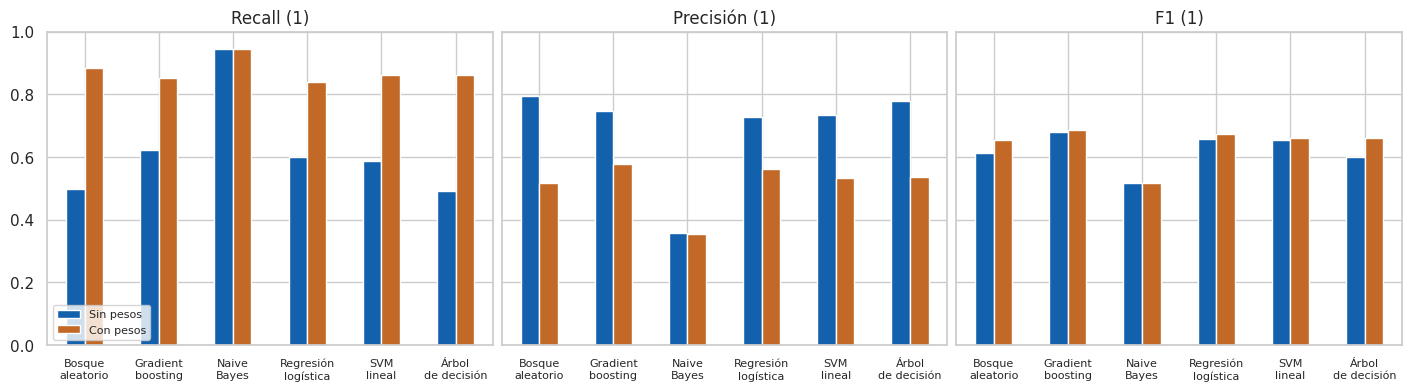

In [29]:
## Recall y precisión de la clase 1, sin pesos y con pesos
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8), layout="constrained", sharey=True)
for ax, metrica in zip(ejes, ["Recall (1)", "Precisión (1)", "F1 (1)"]):
    tabla = comparacion[metrica].unstack("Variante")[["Sin pesos", "Con pesos"]]
    tabla.plot.bar(ax=ax, color=[azul, naranja], rot=0, legend=False)
    ax.set_xticklabels([n.replace(" ", "\n", 1) for n in tabla.index], fontsize=8)
    ax.set(title=metrica, xlabel="", ylim=(0, 1))
ejes[0].legend(fontsize=8, loc="lower left")
plt.show()

Los pesos cambian el punto de equilibrio de los modelos, no su capacidad de ordenar:

- **El recall sube mucho y la precisión baja.** En el GBT el recall pasa de **62,4 % a 85,2 %** y la precisión de 74,8 % a 57,7 %. En el bosque aleatorio el salto es todavía mayor, de 49,9 % a 88,5 %.
- **El F1 mejora un poco en todos**, salvo en Naive Bayes. El que más gana es el árbol de decisión, de 0,602 a 0,661.
- **El ROC AUC casi no se mueve** (en el GBT sigue en 0,913). Es lo esperado, porque los pesos desplazan la frontera de decisión pero el orden de los puntajes es prácticamente el mismo.
- **La exactitud baja**, por ejemplo de 86,1 % a 81,7 % en el GBT, porque ahora hay más falsos positivos.
- **Naive Bayes no cambia**, porque ya estaba marcando casi todo como ingreso alto.

#### ¿Qué variables usa el mejor modelo?

La importancia de un GBT mide cuánto contribuye cada entrada a las divisiones de los árboles. Los nombres de cada posición del vector los recuperé de los metadatos del `VectorAssembler`, como en el taller de Stroke. Además, como la codificación reparte cada variable categórica en varias posiciones, sumo la importancia por variable original.

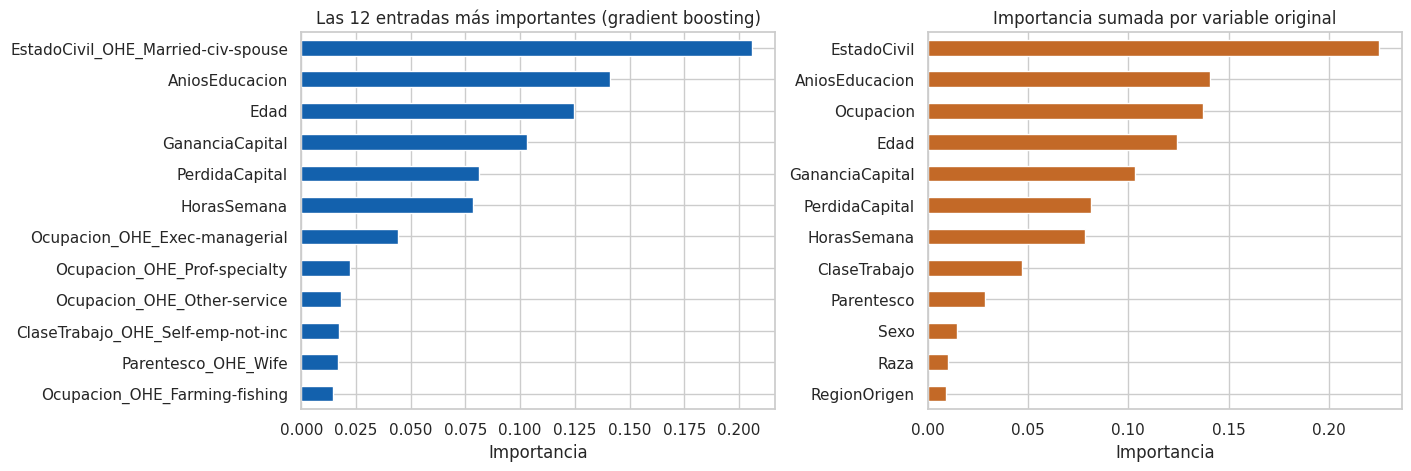

,Importancia
EstadoCivil,0.225
AniosEducacion,0.141
Ocupacion,0.137
Edad,0.124
GananciaCapital,0.103
PerdidaCapital,0.081
HorasSemana,0.078
ClaseTrabajo,0.047
Parentesco,0.029
Sexo,0.015


In [30]:
## Importancia de cada posición del vector en el gradient boosting
gbt = ajustados["Gradient boosting"]
importancias = pd.Series(gbt.featureImportances.toArray(), index=nombres_vector).sort_values(ascending=False)

## El one-hot reparte cada variable categórica en varias posiciones: se suman por variable original
grupos = importancias.groupby(lambda nombre: nombre.split("_OHE")[0]).sum().sort_values(ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
importancias.head(12)[::-1].plot.barh(ax=ax1, color=azul)
ax1.set(title="Las 12 entradas más importantes (gradient boosting)", xlabel="Importancia")
grupos[::-1].plot.barh(ax=ax2, color=naranja)
ax2.set(title="Importancia sumada por variable original", xlabel="Importancia")
plt.show()
display(grupos.round(3).to_frame("Importancia"))

El estado civil es la variable más importante (0,225), y casi toda esa importancia está en un solo indicador, `Married-civ-spouse`. Le siguen los años de educación (0,141), la ocupación (0,137), la edad (0,124) y las dos variables de capital. Coincide con la exploración, donde el estado civil, la educación y la ocupación mostraron los contrastes más fuertes.

`Sexo`, `Raza` y `RegionOrigen` quedan al final, con 1,5 % o menos cada una. Esto no significa que no tengan relación con el ingreso, porque la brecha por sexo es grande. Significa que el modelo obtiene casi la misma información de otras variables, como el parentesco (`Wife`, `Husband`) o la ocupación.

## Análisis de resultados

Las cifras de este resumen se calculan a partir de las tablas de métricas, así que se actualizan si el cuaderno se vuelve a ejecutar.

In [33]:
## Resumen de resultados en texto, calculado desde las tablas de métricas
def coma(valor, decimales=3):
    return f"{valor:.{decimales}f}".replace(".", ",")


def porcentaje(valor):
    return f"{100 * valor:.1f}".replace(".", ",") + " %"


def miles(valor):
    return f"{int(valor):,}".replace(",", ".")


rendimiento = resultados.drop(index=nombre_base)
prevalencia = etiquetas.mean()
exactitud_base = resultados.loc[nombre_base, "Exactitud"]
mejor_auc = rendimiento["ROC AUC"].idxmax()
peor_auc = rendimiento["ROC AUC"].idxmin()
mejor_f1 = rendimiento["F1 (1)"].idxmax()
con_pesos = comparacion.xs("Con pesos", level="Variante")
mejor_pesos = con_pesos["F1 (1)"].idxmax()
vp, fn, fp = con_pesos.loc[mejor_pesos, ["VP", "FN", "FP"]].astype(int)

puntos = [
    f"- La línea base acierta el **{porcentaje(exactitud_base)}** de las filas sin encontrar a ninguna de las "
    f"**{miles(etiquetas.sum())}** personas con ingreso > 50K de la prueba. Los ocho modelos quedan entre "
    f"**{porcentaje(rendimiento['Exactitud'].min())}** y **{porcentaje(rendimiento['Exactitud'].max())}** de exactitud.",
    f"- El ROC AUC va de **{coma(rendimiento['ROC AUC'].min())}** ({peor_auc}) a **{coma(rendimiento['ROC AUC'].max())}** "
    f"({mejor_auc}), y el AUC PR de **{coma(rendimiento['AUC PR'].min())}** a **{coma(rendimiento['AUC PR'].max())}**, "
    f"frente a una proporción de positivos de **{coma(prevalencia)}**.",
    f"- Sin pesos, el mejor F1 de la clase 1 fue el de **{mejor_f1}** (**{coma(rendimiento.loc[mejor_f1, 'F1 (1)'])}**), "
    f"con un recall de **{porcentaje(rendimiento.loc[mejor_f1, 'Recall (1)'])}**.",
    f"- Con pesos, el mejor F1 fue el de **{mejor_pesos}** (**{coma(con_pesos.loc[mejor_pesos, 'F1 (1)'])}**), con un "
    f"recall de **{porcentaje(con_pesos.loc[mejor_pesos, 'Recall (1)'])}**: encontró **{miles(vp)}** de "
    f"**{miles(vp + fn)}** personas con ingreso > 50K a cambio de **{miles(fp)}** falsos positivos.",
]
display(Markdown("\n".join(puntos)))

- La línea base acierta el **76,4 %** de las filas sin encontrar a ninguna de las **3.846** personas con ingreso > 50K de la prueba. Los ocho modelos quedan entre **58,5 %** y **86,1 %** de exactitud.
- El ROC AUC va de **0,855** (Naive Bayes) a **0,913** (Gradient boosting), y el AUC PR de **0,596** a **0,786**, frente a una proporción de positivos de **0,236**.
- Sin pesos, el mejor F1 de la clase 1 fue el de **Gradient boosting** (**0,680**), con un recall de **62,4 %**.
- Con pesos, el mejor F1 fue el de **Gradient boosting** (**0,688**), con un recall de **85,2 %**: encontró **3.276** de **3.846** personas con ingreso > 50K a cambio de **2.404** falsos positivos.

Al juntar estas cifras con la exploración, la lectura es consistente:

- **Siete de los ocho modelos aprenden bastante.** Superan la exactitud de la línea base en 8 a 10 puntos y su ROC AUC queda entre 0,88 y 0,91. Lo que mostró la exploración (el estado civil, la educación, la ocupación y la edad separan las clases) aparece después en la importancia de las variables.
- **El GBT y el perceptrón quedan arriba, pero por poco.** Entre el GBT (0,913) y la SVM lineal (0,901) hay apenas una centésima de ROC AUC. Los modelos lineales ya capturan casi toda la señal, y los que admiten relaciones no lineales agregan un poco más. El árbol solo es el más débil de los siete, aunque es el más fácil de interpretar.
- **Naive Bayes no funcionó con esta preparación.** Su versión gaussiana supone que cada entrada sigue una distribución normal y que todas son independientes. Aquí casi todas las entradas son indicadores de 0 y 1, las variables de capital tienen casi todo en cero, y varias se repiten entre sí (`Husband` casi siempre coincide con `Married-civ-spouse`). El modelo cuenta la misma evidencia varias veces y termina marcando a demasiada gente. En `adult.names`, el Naive Bayes de los autores tiene un error de 16,12 %, pero ese trabaja directamente con las categorías, sin codificarlas.
- **Mis resultados están en línea con los de referencia.** Los algoritmos que los autores probaron con esta misma partición tienen errores entre el **14,05 %** y el **21,42 %**. El error de mi GBT es **13,9 %**. La comparación no es exacta, porque ellos quitaron las filas con faltantes y yo las conservé, pero indica que el resultado es razonable.
- **Con pesos o sin pesos es una decisión de uso.** Sin pesos, el GBT acierta en tres de cada cuatro personas que marca, pero deja por fuera al 38 % de quienes ganan más de 50K. Con pesos encuentra al 85 %, y a cambio se equivoca en cuatro de cada diez que marca. Cuál conviene depende de qué cueste más en la aplicación: un falso positivo o un falso negativo.

## Conclusiones

1. **El mejor modelo fue el *gradient boosting*.** Obtuvo la mayor exactitud (**86,1 %**), el mayor ROC AUC (**0,913**), el mayor AUC PR (**0,786**) y el mayor F1 (**0,680**). El perceptrón multicapa quedó muy cerca (0,907), y la regresión logística, el bosque aleatorio, la máquina de factorización y la SVM lineal quedaron prácticamente empatados alrededor de 0,90.
2. **Probar más modelos del mínimo sirvió para ver los límites.** Si me hubiera quedado con cinco, no habría visto que un modelo puede quedar por debajo de la línea base. Naive Bayes tuvo una exactitud de 58,5 %, frente al 76,4 % de responder siempre 0, y aun así un ROC AUC de 0,855. Ordena razonablemente bien, pero con su umbral por defecto clasifica mal.
3. **La exactitud sola no basta para elegir.** El árbol de decisión y la regresión logística tienen exactitudes casi iguales (84,7 % y 85,3 %), pero el primero encuentra al 49 % de las personas con ingreso alto y la segunda al 60 %. Lo que más cambió mi lectura fue mirar el recall y las matrices de confusión al lado de la exactitud.
4. **Los pesos por clase cambian qué errores comete el modelo.** Con pesos, el GBT pasó de encontrar 2.399 a **3.276** de las 3.846 personas con ingreso alto, a cambio de pasar de 809 a 2.404 falsos positivos. El ROC AUC siguió en 0,913, lo que confirma que los pesos mueven la frontera y no la calidad del orden.
5. **La preparación de datos importó.** El vistazo a los archivos crudos con un RDD me mostró tres detalles que habrían dañado el trabajo sin producir ningún error: el separador con espacio, la línea inicial de `adult.test` y el punto al final de sus etiquetas. Además, conservar los faltantes como categoría me permitió usar las 48.842 filas.
6. **Hay que leer el modelo con cuidado.** Aprende patrones de 1994, incluida la brecha de ingresos entre hombres y mujeres y entre personas de distinto origen. Aunque `Sexo`, `Raza` y `RegionOrigen` tienen poca importancia directa, su efecto llega por otras variables, como el parentesco o la ocupación. El modelo sirve para el ejercicio académico, pero no debería usarse para tomar decisiones sobre personas sin revisar antes cómo se comporta con cada grupo.
7. **Siguiente paso.** Separaría una partición de validación dentro del entrenamiento para escoger el umbral del GBT según cuántos falsos positivos se puedan tolerar, y probaría Naive Bayes con las categorías indexadas en lugar de codificadas. Esta entrega se limita a comparar los modelos con estos datos y a documentar el proceso.

### Referencias

- Becker, B. y Kohavi, R. (1996). *Adult* (Census Income). UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/20/census+income
- Kohavi, R. (1996). *Scaling Up the Accuracy of Naive-Bayes Classifiers: a Decision-Tree Hybrid*. Proceedings of the Second International Conference on Knowledge Discovery and Data Mining. Citado en `adult.names`.
- Apache Spark 3.5.5. *Classification and regression*. https://spark.apache.org/docs/3.5.5/ml-classification-regression.html
- Apache Spark 3.5.5. *CSV Files*. https://spark.apache.org/docs/3.5.5/sql-data-sources-csv.html
- Guía 01 del taller: *Classification Models with PySpark in Bank Dataset* (Kaggle). https://www.kaggle.com/code/ilhansevval/classification-models-with-pyspark-in-bank-dataset/notebook
- Guía 02 del taller: *Adult Income Dataset | From Scratch* (Kaggle). https://www.kaggle.com/code/aditimulye/adult-income-dataset-from-scratch

In [32]:
## Cierro la sesión de Spark para liberar los recursos del clúster
sparkSanchez.stop()